[Github](https://github.com/yxt1106/ecs708-fashion-mnist.git)

In [ ]:
import torch
from torch import nn
import numpy as np
import torchvision
from torchvision import datasets

from sklearn.model_selection import train_test_split
from torch.utils.data import Subset
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

In [2]:
! git clone https://github.com/yxt1106/ecs708-fashion-mnist.git

Cloning into 'ecs708-fashion-mnist'...
remote: Enumerating objects: 115, done.
remote: Counting objects: 100% (38/38), done.
remote: Compressing objects: 100% (36/36), done.
remote: Total 115 (delta 2), reused 38 (delta 2), pack-reused 77 (from 1)
Receiving objects: 100% (115/115), 60.89 MiB | 20.96 MiB/s, done.
Resolving deltas: 100% (24/24), done.
Updating files: 100% (61/61), done.


In [ ]:
!rm -rf /content/ecs708-fashion-mnist/ecs708-fashion-mnist

In [ ]:
!git add .
!git status

fatal: not a git repository (or any of the parent directories): .git
fatal: not a git repository (or any of the parent directories): .git


In [10]:
!git config --global user.email "sghrad1@gmail.com"
!git config --global user.name "yxt1106"

In [ ]:
%cd /content/ecs708-fashion-mnist

!pwd
!ls -la
!git status --short --untracked-files=all

/content/ecs708-fashion-mnist
/content/ecs708-fashion-mnist
total 12
drwxr-xr-x 3 root root 4096 Nov 21 01:00 .
drwxr-xr-x 1 root root 4096 Nov 21 01:08 ..
drwxr-xr-x 7 root root 4096 Nov 21 01:35 .git


In [ ]:
!mkdir -p notebooks configs splits src
!mkdir -p results/logs results/metrics figures scripts

!touch requirements.txt
!touch .gitignore
!touch src/__init__.py
!touch results/experiment_register.csv

!touch notebooks/.gitkeep
!touch configs/.gitkeep
!touch splits/.gitkeep
!touch results/logs/.gitkeep
!touch results/metrics/.gitkeep
!touch figures/.gitkeep
!touch scripts/.gitkeep

In [ ]:
%%writefile README.md

# ECS708 Fashion-MNIST

## Project Overview

Fashion-MNIST classification and clustering experiments.

## Project Structure

- notebooks/: Experiment notebooks
- configs/: Experiment configurations
- splits/: Dataset split indices
- src/: Source code
- results/: Experimental results
- figures/: Generated figures
- scripts/: Utility scripts

## Environment

Google Colab, Python and PyTorch.

Overwriting README.md


In [ ]:
!find . -maxdepth 3 -type f

./README.md
./.gitignore
./figures/.gitkeep
./notebooks/.gitkeep
./requirements.txt
./.git/config
./.git/HEAD
./.git/info/exclude
./.git/description
./.git/index
./.git/hooks/pre-receive.sample
./.git/hooks/sendemail-validate.sample
./.git/hooks/fsmonitor-watchman.sample
./.git/hooks/commit-msg.sample
./.git/hooks/pre-merge-commit.sample
./.git/hooks/prepare-commit-msg.sample
./.git/hooks/pre-push.sample
./.git/hooks/pre-applypatch.sample
./.git/hooks/pre-rebase.sample
./.git/hooks/push-to-checkout.sample
./.git/hooks/post-update.sample
./.git/hooks/update.sample
./.git/hooks/applypatch-msg.sample
./.git/hooks/pre-commit.sample
./.git/COMMIT_EDITMSG
./splits/.gitkeep
./results/metrics/.gitkeep
./results/logs/.gitkeep
./results/experiment_register.csv
./scripts/.gitkeep
./src/__init__.py
./configs/.gitkeep


In [ ]:
!git add .

In [11]:
!git status

!git add .
!git commit -m "Updates"
!git push

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date


In [ ]:
!git status

fatal: not a git repository (or any of the parent directories): .git


In [5]:
from google.colab import userdata
import requests

token = userdata.get("GITHUBTOKEN")

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json"
}

# Check authenticated GitHub account
user_response = requests.get(
    "https://api.github.com/user",
    headers=headers
)

print("Authentication status:", user_response.status_code)

if user_response.ok:
    print("GitHub account:", user_response.json()["login"])

# Check repository access
repo_response = requests.get(
    "https://api.github.com/repos/yxt1106/ecs708-fashion-mnist",
    headers=headers
)

print("Repository access status:", repo_response.status_code)

if repo_response.ok:
    print("Repository:", repo_response.json()["full_name"])
    print("Repository is accessible.")
else:
    print("Repository is not accessible with this token.")

del token

Authentication status: 200
GitHub account: yxt1106
Repository access status: 200
Repository: yxt1106/ecs708-fashion-mnist
Repository is accessible.


In [6]:
from google.colab import userdata
from pathlib import Path
from urllib.parse import quote

token = userdata.get("GITHUBTOKEN")

credential_file = Path.home() / ".git-credentials"

if credential_file.exists():
    credential_file.unlink()

credential_file.write_text(
    f"https://x-access-token:{quote(token, safe='')}@github.com\n"
)

credential_file.chmod(0o600)

!git config --global --unset-all credential.helper

!git config --global credential.helper store

del token

print("Credentials refreshed.")

Credentials refreshed.


In [7]:
%cd /content/ecs708-fashion-mnist

/content/ecs708-fashion-mnist


In [ ]:
!git pull origin main

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
%cd /content

/content


In [ ]:
%cd /content/ecs708-fashion-mnist

/content/ecs708-fashion-mnist


In [ ]:
!git fetch origin

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
!git pull --no-rebase --allow-unrelated-histories origin main

From https://github.com/yxt1106/ecs708-fashion-mnist
 * branch            main       -> FETCH_HEAD
Auto-merging README.md
CONFLICT (add/add): Merge conflict in README.md
Automatic merge failed; fix conflicts and then commit the result.


In [ ]:
!git status

fatal: not a git repository (or any of the parent directories): .git


In [ ]:
%cd /content/ecs708-fashion-mnist

!cat README.md

/content/ecs708-fashion-mnist
<<<<<<< HEAD

# ECS708 Fashion-MNIST

## Project Overview

Fashion-MNIST classification and clustering experiments.

## Project Structure

- notebooks/: Experiment notebooks
- configs/: Experiment configurations
- splits/: Dataset split indices
- src/: Source code
- results/: Experimental results
- figures/: Generated figures
- scripts/: Utility scripts

## Environment

Google Colab, Python and PyTorch.
# ecs708-fashion-mnist
Coursework
>>>>>>> d9b78ce8dc764b58756a3389605a48adae350704


In [ ]:
%cd ecs708-fashion-mnist

/content/ecs708-fashion-mnist


In [13]:
!git status


!git add .
!git commit -m "Update Remark"
!git push

On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
On branch main
Your branch is up to date with 'origin/main'.

nothing to commit, working tree clean
Everything up-to-date


In [ ]:
!git show :2:README.md


# ECS708 Fashion-MNIST

## Project Overview

Fashion-MNIST classification and clustering experiments.

## Project Structure

- notebooks/: Experiment notebooks
- configs/: Experiment configurations
- splits/: Dataset split indices
- src/: Source code
- results/: Experimental results
- figures/: Generated figures
- scripts/: Utility scripts

## Environment

Google Colab, Python and PyTorch.


In [ ]:
!git show :3:README.md

# ecs708-fashion-mnist
Coursework


In [ ]:
%cd /content/ecs708-fashion-mnist

!git checkout --theirs README.md
!git add README.md
!git commit -m "Merge remote repository"
!git push -u origin main

/content/ecs708-fashion-mnist
Updated 1 path from the index
[main db575b3] Merge remote repository
Enumerating objects: 11, done.
Counting objects: 100% (11/11), done.
Delta compression using up to 2 threads
Compressing objects: 100% (6/6), done.
Writing objects: 100% (9/9), 1.04 KiB | 267.00 KiB/s, done.
Total 9 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), done.
To https://github.com/yxt1106/ecs708-fashion-mnist.git
   d9b78ce..db575b3  main -> main
branch 'main' set up to track 'origin/main'.


##**Loading Fashion-MNIST**

Fashion-MNIST contains 28 × 28 greyscale clothing images from ten classes. The code loads the official training and test partitions separately. ToTensor() converts each image to a tensor shaped [1, 28, 28] and scales pixel intensities to 0–1. Labels are converted to NumPy arrays for use with scikit-learn split utilities. Keeping the official test partition separate allows final evaluation on examples not used for fitting or validation.

In [ ]:
transform = transforms.ToTensor()

# Get Train & Test data
train_data = datasets.FashionMNIST(
  root="./data",
  train=True,
  download=True,
  transform=transform
)

test_data = datasets.FashionMNIST(
  root="./data",
  train=False,
  download=True,
  transform=transform
)

train_labels = train_data.targets.numpy()
test_labels = test_data.targets.numpy()

print("Train:", len(train_labels))
print("Test:", len(test_labels))

100%|██████████| 26.4M/26.4M [00:01<00:00, 21.3MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 336kB/s]
100%|██████████| 4.42M/4.42M [00:00<00:00, 6.22MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 9.49MB/s]

Train: 60000
Test: 10000


##**Reproducible training and validation split**
The official training partition is divided into 50,000 training indices and 10,000 validation indices. stratify=train_labels preserves class proportions across the two subsets. Separate seeds are assigned to the main split and later sampling operations. Fixed seeds make the index selection repeatable and support controlled comparisons, although they do not guarantee identical results across every software and hardware environment.

In [ ]:
# Random seeds
# Random seed: Ensures that data is randomly assigned,
# while also guaranteeing that, due to this random assignment,
# no data points end up in the wrong dataset.
SEED_SPLIT = 42
SEED_CPU = 43
SEED_CLUSTER = 44

# Store the index of training dataset
train_all_indices = np.arange(len(train_data))

# Split the official training set, stratified and seeded: 50,000 train / 10,000 validation
train_indices, val_indices = train_test_split(
  train_all_indices,
  test_size=10000,
  random_state=SEED_SPLIT,
  stratify=train_labels
)

print("Train:", len(train_indices))
print("Validation:", len(val_indices))

Train: 50000
Validation: 10000


##**Stratified subsampling**
stratified_sample selects a requested number of indices from an existing index list while preserving its class distribution. It samples local positions, then maps them back to the original dataset indices. The main training list is reduced from 50,000 to 10,000 examples for computational efficiency. The validation set remains 10,000 examples, so the supervised experiments use a smaller training sample while retaining a separate validation partition.

In [ ]:
# Helper function
# Extract specific number of samples from existing data index with a certain proportion
def stratified_sample(base_indices, labels, n_samples, seed):
  local_indices = np.arange(len(base_indices))
  selected_local, _ = train_test_split(
    local_indices,
    train_size=n_samples,
    random_state=seed,
    stratify=labels[base_indices]
  )
  # The indices relative to original dataset
  return base_indices[selected_local]

# Reduced dataset from 5,0000 to 10,000
train_indices = stratified_sample(
  train_indices,
  train_labels,
  n_samples=10000,
  seed=SEED_CPU
)

##**Subsets and data loaders**
Subset objects expose selected examples without copying the underlying images. The notebook creates 3,000/1,000-image subsets for later clustering and feature work, alongside the main training, validation, and test datasets. Training loaders shuffle examples; validation, test, and feature-extraction loaders preserve order so that predictions, labels, and images remain aligned. The compressed index file records seeds and selected indices for reproducibility.

In [ ]:
# Clustering / feature extraction subsets with stratified_sample

# Extract 3000 data from training set
cluster_train_indices = stratified_sample(
  train_indices,
  train_labels,
  n_samples=3000,
  seed=SEED_CLUSTER
)

# Same as above, but this is validation datasets
cluster_val_indices = stratified_sample(
  val_indices,
  train_labels,
  n_samples=1000,
  seed=SEED_CLUSTER
)

test_all_indices = np.arange(len(test_data))

cluster_test_indices = stratified_sample(
  test_all_indices,
  test_labels,
  n_samples=1000,
  seed=SEED_CLUSTER
)

# Create subset from dataset according to specific index
# e.g. train_indices
train_dataset = Subset(
  train_data, train_indices.tolist()
)

val_dataset = Subset(
  train_data, val_indices.tolist()
)

test_dataset = test_data

cluster_train_dataset = Subset(
  train_data, cluster_train_indices.tolist()
)

cluster_val_dataset = Subset(
  train_data, cluster_val_indices.tolist()
)

cluster_test_dataset = Subset(
  test_data, cluster_test_indices.tolist()
)

# Create DataLoaders
# Read the data from dataset to model for training or validation
train_loader = DataLoader(
  train_dataset,
  batch_size=64,
  shuffle=True,
  num_workers=0
)

# CPU-based training option
train_loader = DataLoader(
  train_dataset,
  batch_size=64,
  shuffle=True,
  num_workers=0
)

# Validation and test
val_loader = DataLoader(
  val_dataset,
  batch_size=128,
  shuffle=False,
  num_workers=0
)

test_loader = DataLoader(
  test_dataset,
  batch_size=128,
  shuffle=False,
  num_workers=0
)

# Clustering / feature extraction
cluster_train_loader = DataLoader(
  cluster_train_dataset,
  batch_size=128,
  shuffle=False,
  num_workers=0
)

cluster_val_loader = DataLoader(
  cluster_val_dataset,
  batch_size=128,
  shuffle=False,
  num_workers=0
)

cluster_test_loader = DataLoader(
  cluster_test_dataset,
  batch_size=128,
  shuffle=False,
  num_workers=0
)

np.savez_compressed(
  "fashion_mnist_indices.npz",

  seed_split=SEED_SPLIT,
  seed_cpu=SEED_CPU,
  seed_cluster=SEED_CLUSTER,

  train_indices=train_indices,
  val_indices=val_indices,

  cpu_train_indices=train_indices,

  cluster_train_indices=cluster_train_indices,
  cluster_val_indices=cluster_val_indices,
  cluster_test_indices=cluster_test_indices
)

# The data length we get
print("Main Training:", len(train_dataset))
print("CPU Training:", len(train_dataset))
print("Validation:", len(val_dataset))
print("Test:", len(test_dataset))

print("Cluster Training:", len(cluster_train_dataset))
print("Cluster Validation:", len(cluster_val_dataset))
print("Cluster Test:", len(cluster_test_dataset))

Main Training: 10000
CPU Training: 10000
Validation: 10000
Test: 10000
Cluster Training: 3000
Cluster Validation: 1000
Cluster Test: 1000


In [ ]:
# Class names
class_names = train_data.classes
class_names

['T-shirt/top',
 'Trouser',
 'Pullover',
 'Dress',
 'Coat',
 'Sandal',
 'Shirt',
 'Sneaker',
 'Bag',
 'Ankle boot']

##**Preparing features for classical models**
Scikit-learn expects a two-dimensional feature matrix, so loader_to_numpy flattens each image from [1, 28, 28] to 784 pixel features. It concatenates batches while keeping labels in the same order. Features are stored as float32 and labels as int64. No extra scaling is applied: ToTensor() has already placed pixel values in the 0–1 range.

In [ ]:
# Linear Regression
from sklearn.linear_model import LogisticRegression
def loader_to_numpy(loader):
  images_list = []
  labels_list = []

  for images, labels in loader:
    # [batch_size, 1, 28, 28] -> [batch_size, 784]
    images = images.flatten(start_dim=1)
    images_list.append(images.numpy())
    labels_list.append(labels.numpy())

  X = np.concatenate(images_list).astype(np.float32)
  y = np.concatenate(labels_list).astype(np.int64)
  return X, y


# Training subset
classical_train_loader = DataLoader(
  train_dataset,
  batch_size=256,
  shuffle=False,
  num_workers=0
)

# Validation set
classical_val_loader = DataLoader(
  val_dataset,
  batch_size=256,
  shuffle=False,
  num_workers=0
)


# Extract data
X_train_classical, y_train_classical = loader_to_numpy(
  classical_train_loader
)

X_val_classical, y_val_classical = loader_to_numpy(
  classical_val_loader
)


print("Classical training:", X_train_classical.shape)
print("Validation:", X_val_classical.shape)

Classical training: (10000, 784)
Validation: (10000, 784)


##**Classical classification baselines**
Logistic Regression estimates class probabilities from a linear combination of pixel features; despite its name, this estimator handles discrete class labels. Its C parameter is inverse regularisation strength, so smaller values impose stronger regularisation. Random Forest combines decision trees; here it uses 100 trees, maximum depth 20, and minimum leaf size two. Both models use the same training data, making their validation results directly comparable.

In [ ]:
# 1.Logistic Regression
# We can get the probility of each class
# Class are discrete variables.
# The Linear Regression will not worked because it is used for continous variables
from sklearn.linear_model import LogisticRegression
lr_model = LogisticRegression(
  C=1.0,
  max_iter=500,
  solver="lbfgs"
)

In [ ]:
# #%%writefile -a src/model.py
# 2.Random Forest
# Rely on the consequense of all trees and make decision together
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(
  n_estimators=100, # the number of the trees
  max_depth=20,
  min_samples_leaf=2,
  random_state=SEED_CPU,
  n_jobs=-1
)

In [ ]:
#%%writefile -a src/model.py
# Training two models using exactly the same training data
lr_model.fit(
  X_train_classical, # features
  y_train_classical # labels
)

rf_model.fit(
  X_train_classical,
  y_train_classical
)


print("Both models have been trained.")

Both models have been trained.


##**Validation metrics**
Accuracy gives the overall proportion of correct predictions. Classification reports add per-class precision, recall, F1-score, and support, revealing whether performance differs across clothing categories. Confusion matrices show which true classes are predicted as other classes: diagonal entries are correct predictions and off-diagonal entries are errors. Read these measures together because a single accuracy value can hide class-specific weaknesses.

In [ ]:
#%%writefile src/evaluate.py
# Predictions on the same validation set
# Compare the results of both models(seen in print out)
from sklearn.metrics import (
  accuracy_score,
  classification_report,
  confusion_matrix,
  ConfusionMatrixDisplay
)
import pandas as pd

# Evaluate both models and get results
lr_pred = lr_model.predict(X_val_classical)
rf_pred = rf_model.predict(X_val_classical)


lr_accuracy = accuracy_score(
  y_val_classical,
  lr_pred
)

rf_accuracy = accuracy_score(
  y_val_classical,
  rf_pred
)


accuracy_comparison = pd.DataFrame({
  "Model": ["Logistic Regression", "Random Forest"],
  "Validation Accuracy": [
    lr_accuracy,
    rf_accuracy
  ]
})

display(accuracy_comparison)

,Model,Validation Accuracy
0,Logistic Regression,0.8412
1,Random Forest,0.8603


In [ ]:
#%%writefile -a src/evaluate.py
# Evaluate performance of Logistic Regression and Random Forest on the validation set
# Logistic Regression report

# Get Report of Logistic Regression
lr_report = classification_report(
  y_val_classical,
  lr_pred,
  labels=np.arange(10),
  target_names=class_names,
  output_dict=True,
  zero_division=0
)

lr_table = pd.DataFrame(lr_report).T


# Random Forest report

# Get Report of Random Forest
rf_report = classification_report(
  y_val_classical,
  rf_pred,
  labels=np.arange(10),
  target_names=class_names,
  output_dict=True,
  zero_division=0
)

# Transfer results into DataFrame
rf_table = pd.DataFrame(rf_report).T


# Display class-level results

print("Logistic Regression")

display(
  lr_table.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
  ]
)


print("Random Forest")

display(
  rf_table.loc[
    class_names,
    ["precision", "recall", "f1-score", "support"]
  ]
)

Logistic Regression


,precision,recall,f1-score,support
T-shirt/top,0.786473,0.814,0.800000,1000.0
Trouser,0.967774,0.961,0.964375,1000.0
Pullover,0.729412,0.744,0.736634,1000.0
Dress,0.864865,0.832,0.848114,1000.0
Coat,0.729597,0.742,0.735746,1000.0
Sandal,0.931452,0.924,0.927711,1000.0
Shirt,0.615305,0.595,0.604982,1000.0
Sneaker,0.908092,0.909,0.908546,1000.0
Bag,0.945619,0.939,0.942298,1000.0
Ankle boot,0.933333,0.952,0.942574,1000.0


Random Forest


,precision,recall,f1-score,support
T-shirt/top,0.815280,0.843,0.828909,1000.0
Trouser,0.993789,0.960,0.976602,1000.0
Pullover,0.731022,0.780,0.754717,1000.0
Dress,0.852207,0.888,0.869736,1000.0
Coat,0.737918,0.794,0.764933,1000.0
Sandal,0.954361,0.941,0.947633,1000.0
Shirt,0.715909,0.567,0.632812,1000.0
Sneaker,0.928425,0.908,0.918099,1000.0
Bag,0.946341,0.970,0.958025,1000.0
Ankle boot,0.920696,0.952,0.936087,1000.0


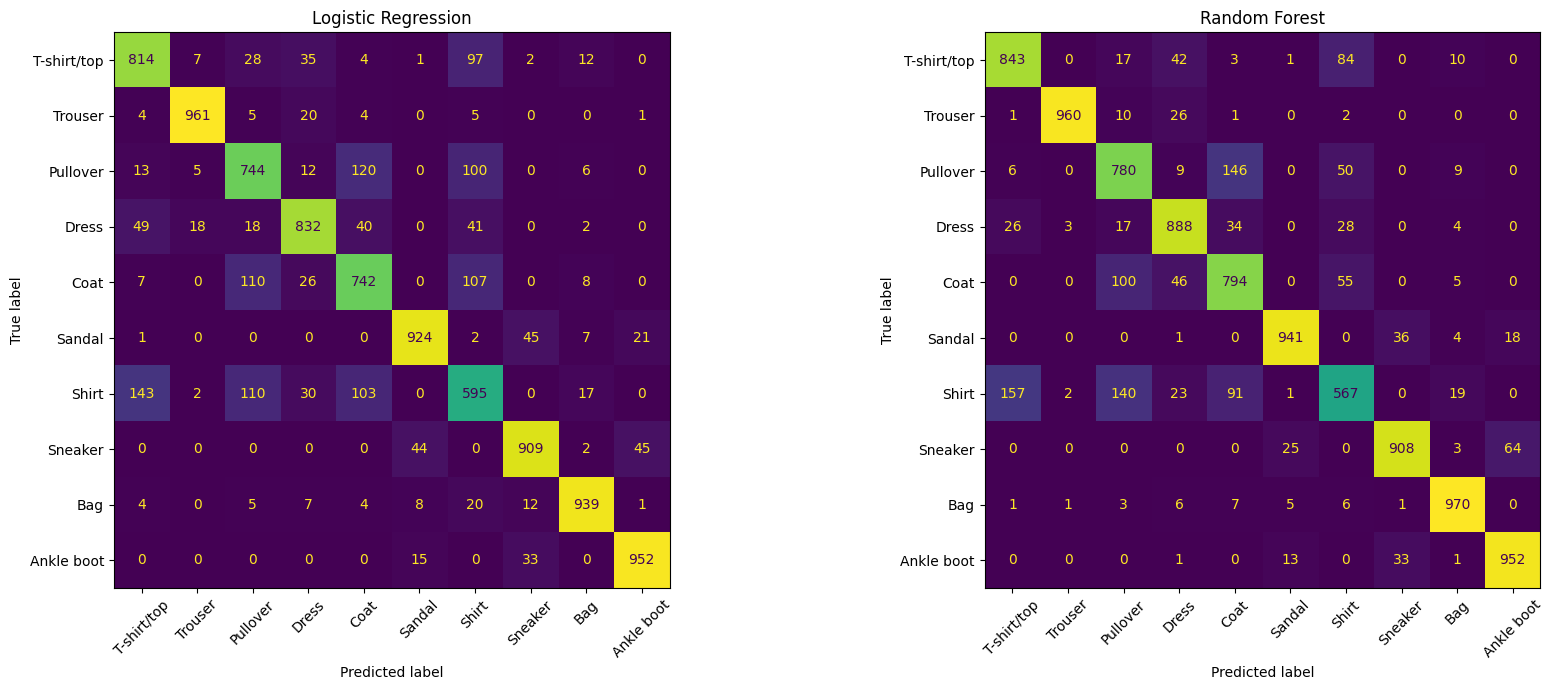

In [ ]:
#%%writefile -a src/evaluate.py
# Draw confusion matrix
# We can get how mach the model pridict is correct by check confusion matrix
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(18, 7))

ConfusionMatrixDisplay.from_predictions(
  y_val_classical, # real labels
  lr_pred, # pridict labels
  display_labels=class_names,
  xticks_rotation=45,
  ax=axes[0],
  colorbar=False
)

axes[0].set_title("Logistic Regression")


ConfusionMatrixDisplay.from_predictions(
  y_val_classical,
  rf_pred,
  display_labels=class_names,
  xticks_rotation=45,
  ax=axes[1],
  colorbar=False
)

axes[1].set_title("Random Forest")

plt.tight_layout()
plt.show()

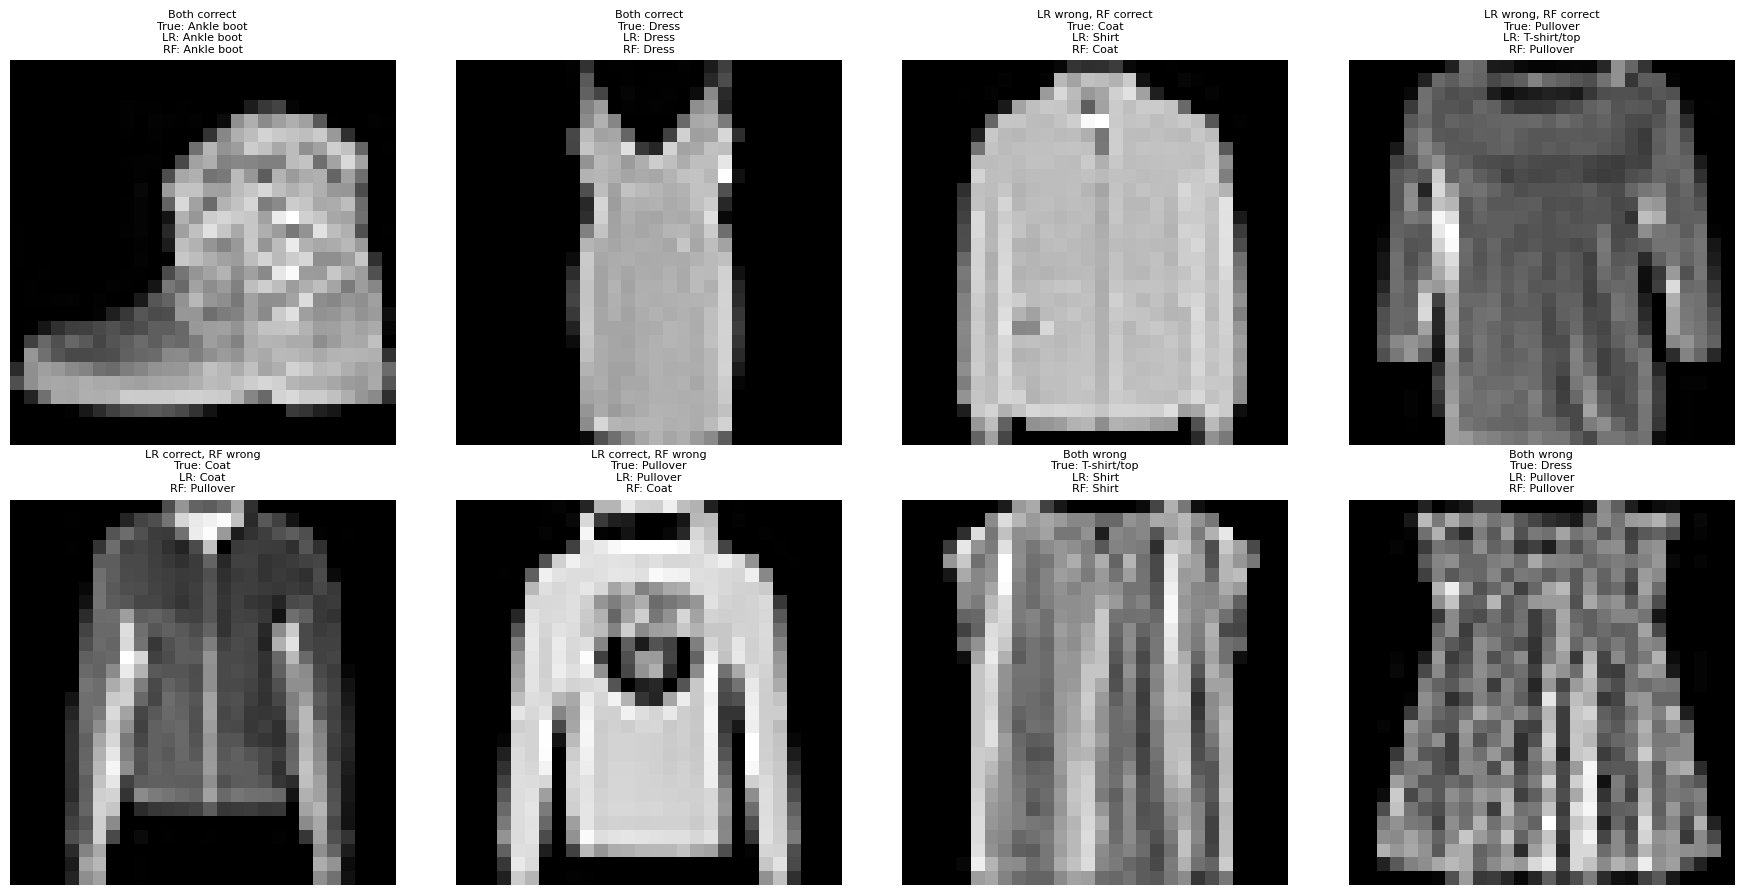

In [ ]:
#%%writefile -a src/evaluate.py
# Identify four types of predictions
# Compare result between Logitisc Regression and Rando Forest
groups = {
  "Both correct": np.where(
    (lr_pred == y_val_classical) &
    (rf_pred == y_val_classical)
  )[0],

  "LR wrong, RF correct": np.where(
    (lr_pred != y_val_classical) &
    (rf_pred == y_val_classical)
  )[0],

  "LR correct, RF wrong": np.where(
    (lr_pred == y_val_classical) &
    (rf_pred != y_val_classical)
  )[0],

  "Both wrong": np.where(
    (lr_pred != y_val_classical) &
    (rf_pred != y_val_classical)
  )[0]
}


# Pick two random examples from each group

rng = np.random.default_rng(42)

selected = []

for group_name, indices in groups.items():
  if len(indices) > 0:
    n = min(2, len(indices))
    chosen = rng.choice(
      indices,
      size=n,
      replace=False
    )
    for idx in chosen:
      selected.append((group_name, idx))


# Visualise the selected images

fig, axes = plt.subplots(2, 4, figsize=(18, 9))

axes = axes.flatten()

for ax, (group_name, idx) in zip(axes, selected):
  image = X_val_classical[idx].reshape(28, 28)
  ax.imshow(image, cmap="gray")
  ax.set_title(
      f"{group_name}\n"
      f"True: {class_names[y_val_classical[idx]]}\n"
      f"LR: {class_names[lr_pred[idx]]}\n"
      f"RF: {class_names[rf_pred[idx]]}",
      fontsize=8
  )
  ax.axis("off")


for ax in axes[len(selected):]:
  ax.axis("off")


plt.tight_layout()
plt.show()

##**Model complexity**
The Logistic Regression experiment varies C; smaller values mean stronger regularisation. The Random Forest experiment varies maximum tree depth, with None allowing unrestricted depth. Training and validation accuracy are recorded for each setting. A high training score but lower validation score may indicate overfitting, while low scores on both can indicate underfitting. The plots visualise this gap, and the best C is selected using validation accuracy.

In [ ]:
#%%writefile -a src/evaluate.py
# The influence of C to model performance
C_values = [0.001, 0.01, 0.1, 1, 10]

lr_complexity_results = []

for c in C_values:
  model = LogisticRegression(
    C=c,
    max_iter=500,
    solver="lbfgs"
  )

  model.fit(
    X_train_classical,
    y_train_classical
  )

  train_accuracy = model.score(
    X_train_classical,
    y_train_classical
  )

  val_accuracy = model.score(
    X_val_classical,
    y_val_classical
  )

  lr_complexity_results.append({
    "C": c,
    "Training Accuracy": train_accuracy,
    "Validation Accuracy": val_accuracy
  })


lr_complexity_df = pd.DataFrame(lr_complexity_results)

display(lr_complexity_df)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


,C,Training Accuracy,Validation Accuracy
0,0.001,0.7764,0.7832
1,0.010,0.8418,0.8373
2,0.100,0.8866,0.8504
3,1.000,0.9243,0.8412
4,10.000,0.9514,0.8140


In [ ]:
#%%writefile -a src/evaluate.py
# Research the performance of Random Forest

depth_values = [3, 5, 10, 20, None] # The test case of the deepth of tree

rf_complexity_results = []

for depth in depth_values:
  model = RandomForestClassifier(
    n_estimators=80, # number of trees
    max_depth=depth,
    min_samples_leaf=2,
    random_state=SEED_CPU,
    n_jobs=-1
  )

  model.fit(
    X_train_classical,
    y_train_classical
  )

  train_accuracy = model.score(
    X_train_classical,
    y_train_classical
  )

  val_accuracy = model.score(
    X_val_classical,
    y_val_classical
  )

  rf_complexity_results.append({
    "Max Depth": str(depth),
    "Training Accuracy": train_accuracy,
    "Validation Accuracy": val_accuracy
  })


rf_complexity_df = pd.DataFrame(rf_complexity_results)

display(rf_complexity_df)

,Max Depth,Training Accuracy,Validation Accuracy
0,3,0.6879,0.6894
1,5,0.7748,0.7658
2,10,0.9198,0.8464
3,20,0.9963,0.8585
4,None,0.9966,0.8624


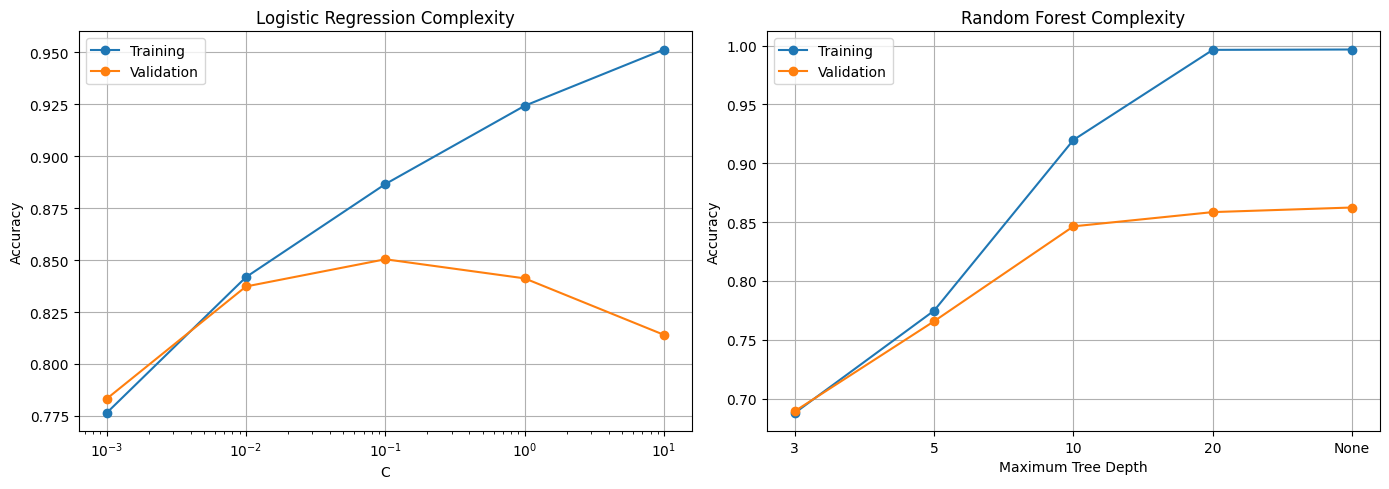

In [ ]:
#%%writefile -a src/evaluate.py
# Generate figures
fig, axes = plt.subplots(1, 2, figsize=(14, 5))


# Logistic Regression

axes[0].plot(
  lr_complexity_df["C"],
  lr_complexity_df["Training Accuracy"],
  marker="o",
  label="Training"
)

axes[0].plot(
  lr_complexity_df["C"],
  lr_complexity_df["Validation Accuracy"],
  marker="o",
  label="Validation"
)

axes[0].set_xscale("log")

axes[0].set_xlabel("C")
axes[0].set_ylabel("Accuracy")

axes[0].set_title("Logistic Regression Complexity")

axes[0].legend()
axes[0].grid(True)


# Random Forest

axes[1].plot(
  rf_complexity_df["Max Depth"],
  rf_complexity_df["Training Accuracy"],
  marker="o",
  label="Training"
)

axes[1].plot(
  rf_complexity_df["Max Depth"],
  rf_complexity_df["Validation Accuracy"],
  marker="o",
  label="Validation"
)

axes[1].set_xlabel("Maximum Tree Depth")
axes[1].set_ylabel("Accuracy")

axes[1].set_title("Random Forest Complexity")

axes[1].legend()
axes[1].grid(True)


plt.tight_layout()
plt.show()

##**Cost-sensitive footwear decision**
The selected Logistic Regression model combines probabilities for class IDs [5, 7, 9] into one footwear probability. Ground-truth labels are converted to the same binary definition. A range of thresholds is tested: probabilities above the threshold are predicted as footwear. False-positive and false-negative rates are calculated, then a custom cost assigns a false negative three times the cost of a false positive. The threshold with minimum average validation cost is selected.

In [ ]:
#%%writefile -a src/evaluate.py
# Choose the best C using validation accuracy
# By iterate with different value of C
best_C = lr_complexity_df.loc[
  lr_complexity_df["Validation Accuracy"].idxmax(),
  "C"
]

print("Best C:", best_C)


# Fit the selected Logistic Regression model

selected_model = LogisticRegression(
  C=best_C,
  max_iter=500,
  solver="lbfgs"
)

selected_model.fit(
  X_train_classical,
  y_train_classical
)


# Get probabilities for all 10 classes

probabilities = selected_model.predict_proba(
  X_val_classical
)


# Sum probabilities for footwear classes
footwear_labels = [5, 7, 9]

footwear_columns = [
  np.where(selected_model.classes_ == label)[0][0]
  for label in footwear_labels
]

p_footwear = probabilities[:, footwear_columns].sum(axis=1)


# Convert the actual labels into binary labels to get results
y_binary = np.isin(
  y_val_classical,
  footwear_labels
).astype(int)


print("Footwear probabilities:", p_footwear[:10])
print("Binary ground truth:", y_binary[:10])

Best C: 0.1
Footwear probabilities: [3.93398417e-07 9.80815051e-01 3.57405858e-06 9.80966707e-01
 3.18274107e-03 1.08117432e-03 5.61710312e-07 9.99493780e-01
 1.04919919e-02 7.67409558e-04]
Binary ground truth: [0 1 0 1 0 0 0 1 0 0]


In [ ]:
#%%writefile -a src/evaluate.py
# Thresholds optimization: Set an threholds to judge the class of item
# if > threholds , it's correct, otherwise it's incorrect
thresholds = np.linspace(0.05, 0.95, 19)

FP_COST = 1
FN_COST = 3

threshold_results = []

for threshold in thresholds:
  y_pred_binary = (
    p_footwear >= threshold
  ).astype(int)

  tn, fp, fn, tp = confusion_matrix(
    y_binary,
    y_pred_binary,
    labels=[0, 1]
  ).ravel()

  # calculate the probilities
  fpr = fp / (fp + tn)
  fnr = fn / (fn + tp)
  total_cost = (
    FP_COST * fp +
    FN_COST * fn
  )
  mean_cost = total_cost / len(y_binary)
  threshold_results.append({
    "Threshold": threshold,
    "FPR": fpr,
    "FNR": fnr,
    "FP": fp,
    "FN": fn,
    "Average Cost": mean_cost
  })


threshold_df = pd.DataFrame(threshold_results)
display(threshold_df)

,Threshold,FPR,FNR,FP,FN,Average Cost
0,0.05,0.026714,0.000333,187,1,0.0190
1,0.10,0.015286,0.000333,107,1,0.0110
2,0.15,0.011286,0.000333,79,1,0.0082
3,0.20,0.009000,0.001000,63,3,0.0072
4,0.25,0.007571,0.001333,53,4,0.0065
5,0.30,0.006000,0.002000,42,6,0.0060
6,0.35,0.005000,0.002667,35,8,0.0059
7,0.40,0.004143,0.003000,29,9,0.0056
8,0.45,0.003857,0.003000,27,9,0.0054
9,0.50,0.003714,0.004000,26,12,0.0062


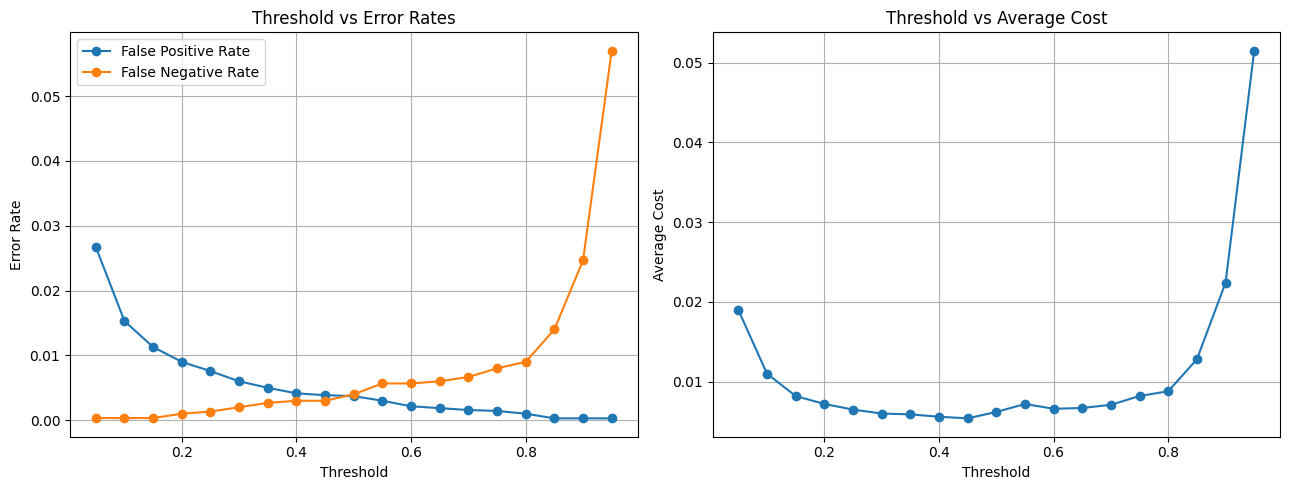

Best threshold:


,8
Threshold,0.450000
FPR,0.003857
FNR,0.003000
FP,27.000000
FN,9.000000
Average Cost,0.005400


In [ ]:
#%%writefile -a src/evaluate.py
fig, axes = plt.subplots(1, 2, figsize=(13, 5))


# Error rates
axes[0].plot(
  threshold_df["Threshold"],
  threshold_df["FPR"],
  marker="o",
  label="False Positive Rate"
)

axes[0].plot(
  threshold_df["Threshold"],
  threshold_df["FNR"],
  marker="o",
  label="False Negative Rate"
)

axes[0].set_xlabel("Threshold")
axes[0].set_ylabel("Error Rate")

axes[0].set_title("Threshold vs Error Rates")

axes[0].legend()
axes[0].grid(True)


# Average cost

axes[1].plot(
  threshold_df["Threshold"],
  threshold_df["Average Cost"],
  marker="o"
)

axes[1].set_xlabel("Threshold")
axes[1].set_ylabel("Average Cost")

axes[1].set_title("Threshold vs Average Cost")

axes[1].grid(True)


plt.tight_layout()
plt.show()


# Find minimum cost threshold

best_threshold = threshold_df.loc[
  threshold_df["Average Cost"].idxmin()
]

print("Best threshold:")
display(best_threshold)

##**Part 2 — Neural Networks: Architecture and Learning**
This part introduces a PyTorch multilayer perceptron (MLP) for the same ten-class task. The model receives flattened pixels, processes them through fully connected hidden layers, and returns ten class scores. Reusing the earlier data partitions makes the neural results easier to compare with the classical baselines. The following cells define the model, training procedure, and reusable experiment function.

In [ ]:
# Part 2 — Neural networks: architecture and learning

In [ ]:
#%%writefile src/train.py
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim

import random
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from torch.utils.data import DataLoader


# Reproducibility
SEED_MLP = 45

def set_seed(seed):

    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)

    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


set_seed(SEED_MLP)

##**MLP architecture**
The MLP maps 784 input pixels through hidden layers specified by hidden_sizes; the baseline (256, 128) therefore has two hidden layers, followed by ten output units. ReLU activations follow the hidden linear layers. The forward method returns logits, not probabilities, because CrossEntropyLoss expects raw class scores. Kaiming initialisation is used for ReLU layers and Xavier initialisation for the output layer. Parameter counting measures model size.

In [ ]:
#%%writefile -a src/model.py
class MLP(nn.Module):
  def __init__(self, hidden_sizes=(256, 128), num_classes=10):
    super().__init__()
    self.hidden_layers = nn.ModuleList()
    input_size = 784

    # Hidden layers
    for hidden_size in hidden_sizes:
      layer = nn.Linear(
        input_size,
        hidden_size
      )
      self.hidden_layers.append(layer)
      input_size = hidden_size

    # Output layer
    self.output_layer = nn.Linear(
      input_size,
      num_classes
    )

    # Weight initialization
    for layer in self.hidden_layers:
      nn.init.kaiming_uniform_(
        layer.weight,
        nonlinearity="relu"
      )
      nn.init.zeros_(layer.bias)

    # Output layer initialization
    nn.init.xavier_uniform_(
      self.output_layer.weight
    )
    nn.init.zeros_(
      self.output_layer.bias
    )

  def forward(self, x):
    # Flatten [batch, 1, 28, 28] -> [batch, 784]
    x = torch.flatten(x, start_dim=1)
    # Hidden layers
    for layer in self.hidden_layers:
      x = F.relu(layer(x))
    # Output logits
    x = self.output_layer(x)
    return x

In [ ]:
baseline_model = MLP(
  hidden_sizes=(256, 128)
)

baseline_params = sum(
  p.numel()
  for p in baseline_model.parameters()
  if p.requires_grad
)

print("Baseline trainable parameters:", baseline_params)

Baseline trainable parameters: 235146


##**Training and evaluation loops**
The training loader shuffles batches using a seeded generator; separate fixed-order loaders evaluate training and validation performance. Each training batch performs a forward pass, cross-entropy calculation, backpropagation, and optimiser update. Evaluation disables gradient tracking and aggregates loss weighted by batch size, alongside the number of correct predictions. This produces dataset-level metrics rather than a simple average of batch metrics.

In [ ]:
#%%writefile -a src/train.py
PART2_BATCH_SIZE = 128

def make_part2_loaders(seed):
  generator = torch.Generator()
  generator.manual_seed(seed)

  # Training loader: shuffled
  part2_train_loader = DataLoader(
    train_dataset,
    batch_size=PART2_BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0
  )

  # Training evaluation loader: fixed order
  part2_train_eval_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
  )

  # Validation loader: fixed order
  part2_val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
  )

  return (
    part2_train_loader,
    part2_train_eval_loader,
    part2_val_loader
  )

# TRaining loop
def train_one_epoch(
  model,
  train_loader,
  criterion,
  optimizer,
  device
):
  model.train()
  for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    # Clear old gradients
    optimizer.zero_grad(set_to_none=True)

    # Forward propagation
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

# Validation Loop
@torch.no_grad()
def evaluate_model(
  model,
  data_loader,
  criterion,
  device
):
  model.eval()
  total_loss = 0.0
  total_correct = 0
  total_samples = 0

  for images, labels in data_loader:
    images = images.to(device)
    labels = labels.to(device)

    # Forward propagation
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Predicted classes
    predictions = outputs.argmax(dim=1)
    batch_size = labels.size(0)
    total_loss += loss.item() * batch_size
    total_correct += (
        predictions == labels
    ).sum().item()
    total_samples += batch_size

  average_loss = total_loss / total_samples
  accuracy = total_correct / total_samples

  return {
    "loss": average_loss,
    "accuracy": accuracy
  }

##**Reusable MLP experiment**
run_mlp_experiment selects CPU or CUDA, sets random seeds, creates fresh loaders and a model, and trains with Adam and cross-entropy loss. After each epoch it records training and validation loss and accuracy. The best checkpoint is chosen by validation loss; min_delta defines a meaningful improvement, and patience controls early stopping. Before returning, the function restores the best checkpoint rather than automatically keeping the final epoch.

In [ ]:
#%%writefile -a src/train.py
# Combine dataLoader, training, evaluate into a function
def run_mlp_experiment(
  hidden_sizes=(256, 128),
  learning_rate=0.001,
  seed=SEED_MLP,
  max_epochs=20,
  patience=5,
  min_delta=1e-4
):

  device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
  )

  print("Using device:", device)
  # Reproducibility
  set_seed(seed)

  # Create DataLoaders
  (
    train_loader,
    train_eval_loader,
    val_loader
  ) = make_part2_loaders(seed)

  # Create model
  model = MLP(
    hidden_sizes=hidden_sizes
  ).to(device)

  # Loss function: Chose CrossEntropy to fit multi classification tasks
  criterion = nn.CrossEntropyLoss()

  # Optimizer
  optimizer = optim.Adam(
    model.parameters(),
    lr=learning_rate
  )

  # Trainable parameter count
  parameter_count = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
  )

  # Report best data
  best_val_loss = float("inf")
  best_epoch = 0
  best_state = None
  epochs_without_improvement = 0
  history = []

  # Main training loop
  for epoch in range(1, max_epochs + 1):
    # Training
    train_one_epoch(
      model,
      train_loader,
      criterion,
      optimizer,
      device
    )

    # Evaluate training performance
    train_metrics = evaluate_model(
      model,
      train_eval_loader,
      criterion,
      device
    )

    # Evaluate validation performance
    val_metrics = evaluate_model(
      model,
      val_loader,
      criterion,
      device
    )

    # Record metrics
    history.append({
      "epoch": epoch,
      "train_loss": train_metrics["loss"],
      "train_accuracy": train_metrics["accuracy"],
      "val_loss": val_metrics["loss"],
      "val_accuracy": val_metrics["accuracy"]
    })

    # Checkpoint using validation loss
    if val_metrics["loss"] < best_val_loss - min_delta:
      best_val_loss = val_metrics["loss"]
      best_epoch = epoch
      best_state = copy.deepcopy(
          model.state_dict()
      )
      epochs_without_improvement = 0
    else:
      epochs_without_improvement += 1


    print(
      f"Epoch [{epoch}/{max_epochs}] "
      f"Train Loss: {train_metrics['loss']:.4f} "
      f"Val Loss: {val_metrics['loss']:.4f} "
      f"Train Acc: {train_metrics['accuracy']:.4f} "
      f"Val Acc: {val_metrics['accuracy']:.4f}"
    )


    # Early stopping
    if epochs_without_improvement >= patience:
      print("Early stopping triggered.")
      break


  # Restore best checkpoint
  if best_state is None:
    raise RuntimeError("No valid model checkpoint was saved.")

  model.load_state_dict(best_state)


  history_df = pd.DataFrame(history)

  best_record = history_df.loc[
    history_df["epoch"] == best_epoch
  ].iloc[0]


  return {
    "model": model,
    "history": history_df,
    "parameter_count": parameter_count,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "best_train_accuracy": best_record["train_accuracy"],
    "best_val_accuracy": best_record["val_accuracy"],
    "epochs_trained": len(history_df)
  }

In [ ]:
# Run the function above
BASELINE_HIDDEN = (256, 128)
BASELINE_LR = 0.001
MAX_EPOCHS = 20
PATIENCE = 5


baseline_result = run_mlp_experiment(
  hidden_sizes=BASELINE_HIDDEN,
  learning_rate=BASELINE_LR,
  seed=SEED_MLP,
  max_epochs=MAX_EPOCHS,
  patience=PATIENCE
)


print("\nBaseline results")

print(
  "Trainable parameters:",
  baseline_result["parameter_count"]
)

print(
  "Best epoch:",
  baseline_result["best_epoch"]
)

print(
  "Best validation loss:",
  baseline_result["best_val_loss"]
)

print(
  "Best validation accuracy:",
  baseline_result["best_val_accuracy"]
)

Using device: cpu
Epoch [1/20] Train Loss: 0.6287 Val Loss: 0.6402 Train Acc: 0.7754 Val Acc: 0.7773
Epoch [2/20] Train Loss: 0.4621 Val Loss: 0.4733 Train Acc: 0.8402 Val Acc: 0.8307
Epoch [3/20] Train Loss: 0.4220 Val Loss: 0.4621 Train Acc: 0.8499 Val Acc: 0.8343
Epoch [4/20] Train Loss: 0.4061 Val Loss: 0.4565 Train Acc: 0.8544 Val Acc: 0.8377
Epoch [5/20] Train Loss: 0.3710 Val Loss: 0.4324 Train Acc: 0.8648 Val Acc: 0.8475
Epoch [6/20] Train Loss: 0.3613 Val Loss: 0.4282 Train Acc: 0.8691 Val Acc: 0.8474
Epoch [7/20] Train Loss: 0.3103 Val Loss: 0.3938 Train Acc: 0.8877 Val Acc: 0.8611
Epoch [8/20] Train Loss: 0.2845 Val Loss: 0.3854 Train Acc: 0.8976 Val Acc: 0.8645
Epoch [9/20] Train Loss: 0.2763 Val Loss: 0.3758 Train Acc: 0.9016 Val Acc: 0.8651
Epoch [10/20] Train Loss: 0.2602 Val Loss: 0.3815 Train Acc: 0.9069 Val Acc: 0.8635
Epoch [11/20] Train Loss: 0.2484 Val Loss: 0.3764 Train Acc: 0.9116 Val Acc: 0.8684
Epoch [12/20] Train Loss: 0.2198 Val Loss: 0.3654 Train Acc: 0.9242

##**Experiment A: network capacity**
Three architectures are compared: small (128, 64), baseline (256, 128), and large (512, 256). The learning rate, data, seed, epoch limit, and early-stopping settings remain fixed, making hidden-layer width the principal variable. The summary records parameter count and best-checkpoint metrics. More parameters increase capacity but do not guarantee better validation performance; learning curves help reveal overfitting.

In [ ]:
# Experiment A: Capacity
capacity_results = {}

# The differecnce between three models is the number of nuerons in each layer

# Small MLP
capacity_results["Small (128, 64)"] = run_mlp_experiment(
  hidden_sizes=(128, 64),
  learning_rate=BASELINE_LR,
  seed=SEED_MLP,
  max_epochs=MAX_EPOCHS,
  patience=PATIENCE
)


# Baseline MLP
capacity_results["Baseline (256, 128)"] = baseline_result


# Large MLP
capacity_results["Large (512, 256)"] = run_mlp_experiment(
  hidden_sizes=(512, 256),
  learning_rate=BASELINE_LR,
  seed=SEED_MLP,
  max_epochs=MAX_EPOCHS,
  patience=PATIENCE
)

Using device: cpu
Epoch [1/20] Train Loss: 0.6458 Val Loss: 0.6585 Train Acc: 0.7706 Val Acc: 0.7726
Epoch [2/20] Train Loss: 0.4889 Val Loss: 0.4994 Train Acc: 0.8352 Val Acc: 0.8272
Epoch [3/20] Train Loss: 0.4495 Val Loss: 0.4758 Train Acc: 0.8436 Val Acc: 0.8336
Epoch [4/20] Train Loss: 0.4330 Val Loss: 0.4704 Train Acc: 0.8453 Val Acc: 0.8312
Epoch [5/20] Train Loss: 0.4163 Val Loss: 0.4624 Train Acc: 0.8481 Val Acc: 0.8363
Epoch [6/20] Train Loss: 0.3837 Val Loss: 0.4422 Train Acc: 0.8638 Val Acc: 0.8462
Epoch [7/20] Train Loss: 0.3511 Val Loss: 0.4192 Train Acc: 0.8756 Val Acc: 0.8538
Epoch [8/20] Train Loss: 0.3343 Val Loss: 0.4153 Train Acc: 0.8805 Val Acc: 0.8532
Epoch [9/20] Train Loss: 0.3094 Val Loss: 0.3952 Train Acc: 0.8915 Val Acc: 0.8600
Epoch [10/20] Train Loss: 0.3048 Val Loss: 0.3996 Train Acc: 0.8927 Val Acc: 0.8590
Epoch [11/20] Train Loss: 0.2963 Val Loss: 0.4070 Train Acc: 0.8943 Val Acc: 0.8575
Epoch [12/20] Train Loss: 0.2678 Val Loss: 0.3919 Train Acc: 0.9062

In [ ]:
# Store the result in DataFrame and show it
capacity_summary = []

for name, result in capacity_results.items():
  capacity_summary.append({
    "Architecture": name,
    "Parameters": result["parameter_count"],
    "Best Epoch": result["best_epoch"],
    "Epocs Trained": result["epochs_trained"],
    "Train Accuracy": result["best_train_accuracy"],
    "Validation Accuracy": result["best_val_accuracy"],
    "Validation Loss": result["best_val_loss"]
  })


capacity_summary_df = pd.DataFrame(capacity_summary)

display(capacity_summary_df)

,Architecture,Parameters,Best Epoch,Epocs Trained,Train Accuracy,Validation Accuracy,Validation Loss
0,"Small (128, 64)",109386,14,19,0.9141,0.8628,0.382676
1,"Baseline (256, 128)",235146,12,17,0.9242,0.8707,0.365430
2,"Large (512, 256)",535818,11,16,0.9303,0.8757,0.363133


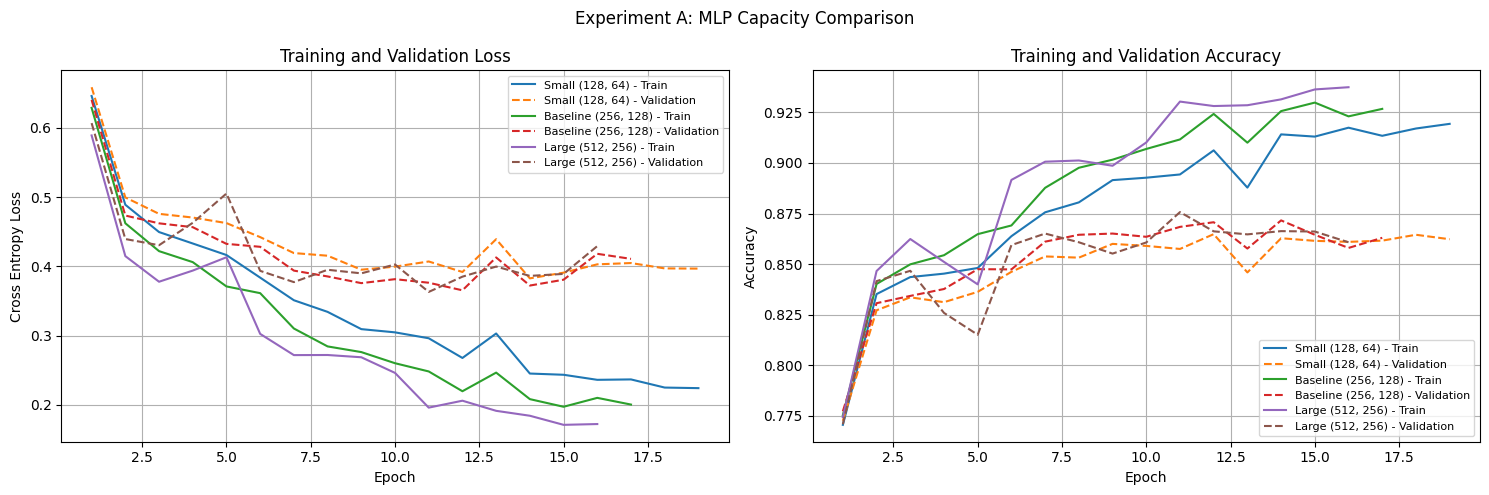

In [ ]:
# Visualization
def plot_learning_curves(results, title):
  fig, axes = plt.subplots(1, 2, figsize=(15, 5))

  # Loss curves
  for name, result in results.items():
    history = result["history"]
    epochs = history["epoch"]
    axes[0].plot(
      epochs,
      history["train_loss"],
      label=f"{name} - Train"
    )
    axes[0].plot(
      epochs,
      history["val_loss"],
      linestyle="--",
      label=f"{name} - Validation"
    )


  axes[0].set_xlabel("Epoch")
  axes[0].set_ylabel("Cross Entropy Loss")
  axes[0].set_title("Training and Validation Loss")
  axes[0].legend(fontsize=8)
  axes[0].grid(True)


  # Accuracy curves
  for name, result in results.items():
    history = result["history"]
    epochs = history["epoch"]
    axes[1].plot(
      epochs,
      history["train_accuracy"],
      label=f"{name} - Train"
    )
    axes[1].plot(
      epochs,
      history["val_accuracy"],
      linestyle="--",
      label=f"{name} - Validation"
    )


  axes[1].set_xlabel("Epoch")
  axes[1].set_ylabel("Accuracy")
  axes[1].set_title("Training and Validation Accuracy")
  axes[1].legend(fontsize=8)
  axes[1].grid(True)


  fig.suptitle(title)

  plt.tight_layout()
  plt.show()


plot_learning_curves(
  capacity_results,
  "Experiment A: MLP Capacity Comparison"
)

In [ ]:
hidden_sizes = (256, 128)

##**Experiment B: learning rate**
The architecture is fixed at the baseline size while Adam learning rates of 0.0001, 0.001, and 0.01 are tested. A rate that is too small may learn slowly; a rate that is too large may produce unstable updates. The same summary metrics and learning-curve plots support comparison. The baseline result is reused for 0.001, avoiding a duplicate training run.

In [ ]:
# Experiment B: Optimisation
# The influence of different learning rate to model
optimisation_results = {}


# Low learning rate
optimisation_results["LR = 0.0001"] = run_mlp_experiment(
  hidden_sizes=BASELINE_HIDDEN,
  learning_rate=0.0001,
  seed=SEED_MLP,
  max_epochs=MAX_EPOCHS,
  patience=PATIENCE
)


# Baseline learning rate
optimisation_results["LR = 0.001"] = baseline_result


# High learning rate
optimisation_results["LR = 0.01"] = run_mlp_experiment(
  hidden_sizes=BASELINE_HIDDEN,
  learning_rate=0.01,
  seed=SEED_MLP,
  max_epochs=MAX_EPOCHS,
  patience=PATIENCE
)

Using device: cpu
Epoch [1/20] Train Loss: 1.0253 Val Loss: 1.0329 Train Acc: 0.6793 Val Acc: 0.6725
Epoch [2/20] Train Loss: 0.7400 Val Loss: 0.7441 Train Acc: 0.7599 Val Acc: 0.7594
Epoch [3/20] Train Loss: 0.6286 Val Loss: 0.6343 Train Acc: 0.8036 Val Acc: 0.8018
Epoch [4/20] Train Loss: 0.5669 Val Loss: 0.5740 Train Acc: 0.8206 Val Acc: 0.8172
Epoch [5/20] Train Loss: 0.5270 Val Loss: 0.5365 Train Acc: 0.8295 Val Acc: 0.8292
Epoch [6/20] Train Loss: 0.4971 Val Loss: 0.5089 Train Acc: 0.8352 Val Acc: 0.8307
Epoch [7/20] Train Loss: 0.4831 Val Loss: 0.4961 Train Acc: 0.8364 Val Acc: 0.8333
Epoch [8/20] Train Loss: 0.4579 Val Loss: 0.4746 Train Acc: 0.8486 Val Acc: 0.8400
Epoch [9/20] Train Loss: 0.4407 Val Loss: 0.4621 Train Acc: 0.8534 Val Acc: 0.8448
Epoch [10/20] Train Loss: 0.4356 Val Loss: 0.4565 Train Acc: 0.8514 Val Acc: 0.8440
Epoch [11/20] Train Loss: 0.4131 Val Loss: 0.4413 Train Acc: 0.8596 Val Acc: 0.8477
Epoch [12/20] Train Loss: 0.4072 Val Loss: 0.4409 Train Acc: 0.8644

In [ ]:
optimisation_summary = []

for name, result in optimisation_results.items():
  optimisation_summary.append({
    "Learning Rate": name,
    "Parameters": result["parameter_count"],
    "Best Epoch": result["best_epoch"],
    "Epochs Trained": result["epochs_trained"],
    "Train Accuracy": result["best_train_accuracy"],
    "Validation Accuracy": result["best_val_accuracy"],
    "Validation Loss": result["best_val_loss"]
  })


optimisation_summary_df = pd.DataFrame(
  optimisation_summary
)

display(optimisation_summary_df)

,Learning Rate,Parameters,Best Epoch,Epochs Trained,Train Accuracy,Validation Accuracy,Validation Loss
0,LR = 0.0001,235146,20,20,0.8862,0.8607,0.396809
1,LR = 0.001,235146,12,17,0.9242,0.8707,0.365430
2,LR = 0.01,235146,8,13,0.8809,0.8524,0.404680


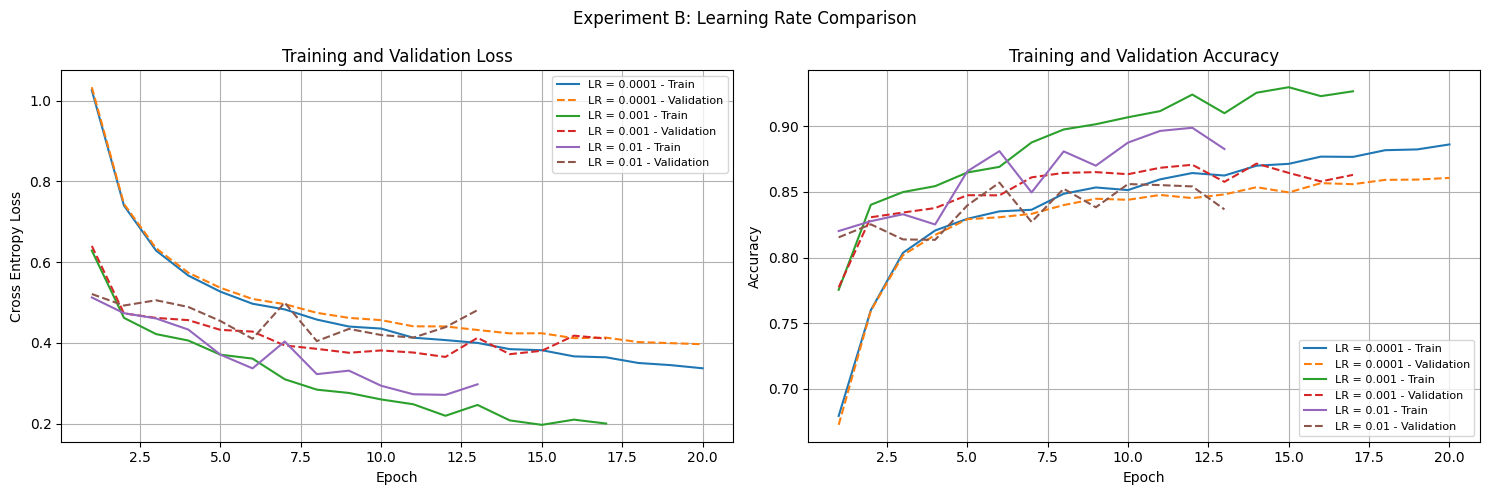

In [ ]:
plot_learning_curves(
    optimisation_results,
    "Experiment B: Learning Rate Comparison"
)

In [ ]:
compact_summary = pd.DataFrame({
  "Experiment": [
    "Capacity - Small",
    "Capacity - Baseline",
    "Capacity - Large",
    "Optimisation - Low LR",
    "Optimisation - Baseline LR",
    "Optimisation - High LR"
  ],

  "Parameters": [
    capacity_results["Small (128, 64)"]["parameter_count"],
    capacity_results["Baseline (256, 128)"]["parameter_count"],
    capacity_results["Large (512, 256)"]["parameter_count"],

    optimisation_results["LR = 0.0001"]["parameter_count"],
    optimisation_results["LR = 0.001"]["parameter_count"],
    optimisation_results["LR = 0.01"]["parameter_count"]
  ],

  "Best Epoch": [
    capacity_results["Small (128, 64)"]["best_epoch"],
    capacity_results["Baseline (256, 128)"]["best_epoch"],
    capacity_results["Large (512, 256)"]["best_epoch"],

    optimisation_results["LR = 0.0001"]["best_epoch"],
    optimisation_results["LR = 0.001"]["best_epoch"],
    optimisation_results["LR = 0.01"]["best_epoch"]
  ],

  "Validation Accuracy": [
    capacity_results["Small (128, 64)"]["best_val_accuracy"],
    capacity_results["Baseline (256, 128)"]["best_val_accuracy"],
    capacity_results["Large (512, 256)"]["best_val_accuracy"],

    optimisation_results["LR = 0.0001"]["best_val_accuracy"],
    optimisation_results["LR = 0.001"]["best_val_accuracy"],
    optimisation_results["LR = 0.01"]["best_val_accuracy"]
  ]
})

display(compact_summary)

,Experiment,Parameters,Best Epoch,Validation Accuracy
0,Capacity - Small,109386,14,0.8628
1,Capacity - Baseline,235146,12,0.8707
2,Capacity - Large,535818,11,0.8757
3,Optimisation - Low LR,235146,20,0.8607
4,Optimisation - Baseline LR,235146,12,0.8707
5,Optimisation - High LR,235146,8,0.8524


##**Part 3 — Regularisation and Generalisation**
RegularizedMLP adds dropout after each hidden ReLU activation. During training, dropout randomly removes a proportion of activations; p=0.3 is tested here. The second method is L2 weight penalisation: the squared weights are summed and scaled by l2_lambda, then added to the training cross-entropy objective. The three configurations are no regularisation, dropout, and L2 with coefficient 1e-4. Reported evaluation loss remains cross-entropy, keeping predictive performance separate from the training penalty.

In [ ]:
class RegularizedMLP(nn.Module):
  def __init__(
    self,
    hidden_sizes=(256, 128),
    num_classes=10,
    dropout_p=0.0
  ):

    super().__init__()
    self.hidden_layers = nn.ModuleList()
    input_size = 784

    # Create hidden layers
    for hidden_size in hidden_sizes:
      layer = nn.Linear(
        input_size,
        hidden_size
      )

      self.hidden_layers.append(layer)
      input_size = hidden_size


    # Output layer
    self.output_layer = nn.Linear(
      input_size,
      num_classes
    )


    # Dropout layers to prevent overfittede
    self.dropouts = nn.ModuleList([
      nn.Dropout(p=dropout_p)
      for _ in hidden_sizes
    ])


    # Weight initialisation
    for layer in self.hidden_layers:
      nn.init.kaiming_uniform_(
        layer.weight,
        nonlinearity="relu"
      )

      nn.init.zeros_(layer.bias)


    # Output initialisation
    nn.init.xavier_uniform_(
      self.output_layer.weight
    )

    nn.init.zeros_(
      self.output_layer.bias
    )


  def forward(self, x):
    # Flatten image: Flatten image dimension(the pixels of height and width)
    x = torch.flatten(
      x,
      start_dim=1
    )

    # Hidden layers
    for layer, dropout in zip(
      self.hidden_layers,
      self.dropouts
    ):
      x = F.relu(layer(x))# activate
      x = dropout(x)


    # Output logits
    x = self.output_layer(x)

    return x

In [ ]:
# Create three configurations

model_none = RegularizedMLP(
  hidden_sizes=(256, 128),
  dropout_p=0.0
)

model_dropout = RegularizedMLP(
  hidden_sizes=(256, 128),
  dropout_p=0.3
)

model_l2 = RegularizedMLP(
  hidden_sizes=(256, 128),
  dropout_p=0.0
)


def count_parameters(model):
  return sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
  )


parameter_summary = pd.DataFrame({

  "Configuration": [
    "No regularisation",
    "Dropout",
    "L2"
  ],

  "Trainable Parameters": [
    count_parameters(model_none),
    count_parameters(model_dropout),
    count_parameters(model_l2)
  ]

})

display(parameter_summary)

,Configuration,Trainable Parameters
0,No regularisation,235146
1,Dropout,235146
2,L2,235146


##**Repeated runs across seeds**
Each regularisation setting is repeated with seeds 45, 46, and 47 to measure sensitivity to random initialisation and shuffled batches. These experiments use a fixed 20-epoch schedule and retain the best validation-loss checkpoint. Tables report best and final metrics, while the generalisation gap is final training accuracy minus final validation accuracy. Mean and standard deviation across seeds summarise typical performance and run-to-run variability.

In [ ]:
PART3_SEEDS = [45, 46, 47] # Reduce randomness

PART3_BATCH_SIZE = 128
# epoch: The model usually needs to observe the training samples multiple times
# and gradually adjust the weights to learn effective features.
PART3_EPOCHS = 20
PART3_LR = 0.001

def set_part3_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
      torch.cuda.manual_seed_all(seed)
    # Use deterministic algorithms to ensure the calculation results remain the same.
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

def make_part3_loaders(seed):
  # Generateor is an independent random number generator object
  # that can be used to specifically control the random processes within a `DataLoader`.
  generator = torch.Generator()
  generator.manual_seed(seed)

  train_loader = DataLoader(
    train_dataset,
    batch_size=PART3_BATCH_SIZE,
    shuffle=True,
    generator=generator,
    num_workers=0
  )

  # Use training data to evaluate
  # Set shuffle to false to avoid disrupting the data
  train_eval_loader = DataLoader(
    train_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
  )

  # Evaluate the model's performance on unseen data.
  val_loader = DataLoader(
    val_dataset,
    batch_size=256,
    shuffle=False,
    num_workers=0
  )


  return (
    train_loader,
    train_eval_loader,
    val_loader
  )

In [ ]:
def l2_weight_penalty(model): # Penalty mechanisms prevent overfitting.
  penalty = 0.0
  for name, parameter in model.named_parameters():
    if name.endswith("weight"):
      penalty = penalty + torch.sum(
        parameter ** 2
      )
  return 0.5 * penalty

In [ ]:
def train_one_epoch_part3(
  model,
  train_loader,
  criterion,
  optimizer,
  device,
  l2_lambda=0.0
):

  model.train()

  for images, labels in train_loader:
    images = images.to(device)
    labels = labels.to(device)

    # Clear previous gradients
    optimizer.zero_grad(set_to_none=True)

    # Forward propagation
    outputs = model(images)

    # Original classification loss
    ce_loss = criterion(
        outputs,
        labels
    )

    # L2 regularisation penalty
    regularisation_loss = (
        l2_lambda * l2_weight_penalty(model)
    )

    # Total training objective
    total_loss = (
        ce_loss + regularisation_loss
    )

    # Backpropagation
    total_loss.backward()

    # Parameter update
    optimizer.step()

In [ ]:
# Evaluation function to calculate the loss and accuracy on a training or validation set.
@torch.no_grad() # Close gradient calculation(because it's evaluate)
def evaluate_part3(
  model,
  data_loader,
  criterion,
  device
):
  # In evalucation, dropout no longer performs random dropping, batch normalization uses running statistics.
  model.eval()
  total_loss = 0.0
  total_correct = 0
  total_samples = 0


  for images, labels in data_loader:
    images = images.to(device)
    labels = labels.to(device)

    outputs = model(images)

    # Cross-entropy only
    loss = criterion(
      outputs,
      labels
    )

    predictions = outputs.argmax(dim=1)
    batch_size = labels.size(0)

    total_loss += loss.item() * batch_size
    total_correct += (
      predictions == labels
    ).sum().item()
    total_samples += batch_size

  return {
    "loss": total_loss / total_samples,
    "accuracy": total_correct / total_samples
  }

In [ ]:
def run_part3_experiment(
  dropout_p=0.0,
  l2_lambda=0.0,
  seed=45
):

  device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
  )

  print("Using device:", device)
  # Set random seeds
  set_part3_seed(seed)

  # Create DataLoaders
  (
    train_loader,
    train_eval_loader,
    val_loader
  ) = make_part3_loaders(seed)

  # Create MLP model
  model = RegularizedMLP(
    hidden_sizes=(256, 128),
    dropout_p=dropout_p
  ).to(device)

  # Loss function
  criterion = nn.CrossEntropyLoss()

  # Optimizer
  optimizer = optim.Adam(
    model.parameters(),
    lr=PART3_LR
  )

  # Count parameters
  parameter_count = count_parameters(model)

  # Checkpoint
  best_val_loss = float("inf")
  best_epoch = 0
  best_state = None

  history = []

  # Fixed training schedule: 20 epochs
  for epoch in range(1, PART3_EPOCHS + 1):
    # The tasks of each training round:
    # - Updating model parameters using the training set.
    # - Checking the model's performance on the training data using a training evaluation set.
    # - Checking the model's performance on data not used for parameter updates using a validation set.
    # Training
    train_one_epoch_part3(
      model,
      train_loader,
      criterion,
      optimizer,
      device,
      l2_lambda=l2_lambda
    )


    # Training performance
    train_metrics = evaluate_part3(
      model,
      train_eval_loader,
      criterion,
      device
    )


    # Validation performance
    val_metrics = evaluate_part3(
      model,
      val_loader,
      criterion,
      device
    )


    # Record learning curves
    history.append({
      "epoch": epoch,
      "train_ce": train_metrics["loss"],
      "val_ce": val_metrics["loss"],
      "train_accuracy": train_metrics["accuracy"],
      "val_accuracy": val_metrics["accuracy"]
    })


    # Save best validation checkpoint
    if val_metrics["loss"] < best_val_loss:
      best_val_loss = val_metrics["loss"]
      best_epoch = epoch
      best_state = copy.deepcopy(
        model.state_dict()
      )


    print(
      f"Epoch [{epoch}/{PART3_EPOCHS}] "
      f"Train CE: {train_metrics['loss']:.4f} "
      f"Val CE: {val_metrics['loss']:.4f} "
      f"Train Acc: {train_metrics['accuracy']:.4f} "
      f"Val Acc: {val_metrics['accuracy']:.4f}"
    )


  # Restore best validation checkpoint
  if best_state is None:
    raise RuntimeError(
      "No valid checkpoint was saved."
    )
  model.load_state_dict(best_state)
  history_df = pd.DataFrame(history)

  # Metrics at the best checkpoint
  best_record = history_df.loc[
    history_df["epoch"] == best_epoch
  ].iloc[0]

  # Metrics at the final epoch
  final_record = history_df.iloc[-1]


  return {
    "model": model,
    "history": history_df,
    "parameter_count": parameter_count,
    "best_epoch": best_epoch,
    "best_val_loss": best_val_loss,
    "best_train_accuracy": best_record["train_accuracy"],
    "best_val_accuracy": best_record["val_accuracy"],
    "final_train_accuracy": final_record["train_accuracy"],
    "final_val_accuracy": final_record["val_accuracy"],
    "final_train_loss": final_record["train_ce"],
    "final_val_loss": final_record["val_ce"]
  }

In [ ]:
# Define the three types of experiments to be compared
PART3_CONFIGS = {
  "No regularisation": { # No dropout
    "dropout_p": 0.0,
    "l2_lambda": 0.0
  },


  "Dropout (p=0.3)": {
    "dropout_p": 0.3,
    "l2_lambda": 0.0
  },

  # Applying a penalty to larger model weights limits their excessive growth,
  # to encourage the model to learn smoother, more constrained parameters.
  "L2 (lambda=1e-4)": {
    "dropout_p": 0.0,
    "l2_lambda": 1e-4
  }
}

In [ ]:
part3_results = {}


for config_name, config in PART3_CONFIGS.items():
  for seed in PART3_SEEDS:
    print("\n" + "=" * 60)
    print("Configuration:", config_name)
    print("Seed:", seed)
    print("=" * 60)

    result = run_part3_experiment(
      dropout_p=config["dropout_p"],
      l2_lambda=config["l2_lambda"],
      seed=seed
    )


    part3_results[
      (config_name, seed)
    ] = result


Configuration: No regularisation
Seed: 45
Using device: cpu
Epoch [1/20] Train CE: 0.6287 Val CE: 0.6402 Train Acc: 0.7754 Val Acc: 0.7773
Epoch [2/20] Train CE: 0.4621 Val CE: 0.4733 Train Acc: 0.8402 Val Acc: 0.8307
Epoch [3/20] Train CE: 0.4220 Val CE: 0.4621 Train Acc: 0.8499 Val Acc: 0.8343
Epoch [4/20] Train CE: 0.4061 Val CE: 0.4565 Train Acc: 0.8544 Val Acc: 0.8377
Epoch [5/20] Train CE: 0.3710 Val CE: 0.4324 Train Acc: 0.8648 Val Acc: 0.8475
Epoch [6/20] Train CE: 0.3613 Val CE: 0.4282 Train Acc: 0.8691 Val Acc: 0.8474
Epoch [7/20] Train CE: 0.3103 Val CE: 0.3938 Train Acc: 0.8877 Val Acc: 0.8611
Epoch [8/20] Train CE: 0.2845 Val CE: 0.3854 Train Acc: 0.8976 Val Acc: 0.8645
Epoch [9/20] Train CE: 0.2763 Val CE: 0.3758 Train Acc: 0.9016 Val Acc: 0.8651
Epoch [10/20] Train CE: 0.2602 Val CE: 0.3815 Train Acc: 0.9069 Val Acc: 0.8635
Epoch [11/20] Train CE: 0.2484 Val CE: 0.3764 Train Acc: 0.9116 Val Acc: 0.8684
Epoch [12/20] Train CE: 0.2198 Val CE: 0.3654 Train Acc: 0.9242 Val 

In [ ]:
seed_results = []

for (config_name, seed), result in part3_results.items():
  seed_results.append({
    "Configuration": config_name,
    "Seed": seed,
    "Parameters": result["parameter_count"],
    "Best Epoch": result["best_epoch"],
    "Best Validation Loss": result["best_val_loss"],
    "Best Validation Accuracy": result["best_val_accuracy"],
    "Final Training Accuracy": result["final_train_accuracy"],
    "Final Validation Accuracy": result["final_val_accuracy"],
    "Final Generalisation Gap": (
      result["final_train_accuracy"]
      - result["final_val_accuracy"]
    )
  })


seed_summary_df = pd.DataFrame(seed_results)

display(
  seed_summary_df.sort_values(
    ["Configuration", "Seed"]
  )
)

,Configuration,Seed,Parameters,Best Epoch,Best Validation Loss,Best Validation Accuracy,Final Training Accuracy,Final Validation Accuracy,Final Generalisation Gap
3,Dropout (p=0.3),45,235146,19,0.359425,0.8748,0.9147,0.8726,0.0421
4,Dropout (p=0.3),46,235146,20,0.342753,0.8774,0.9149,0.8774,0.0375
5,Dropout (p=0.3),47,235146,16,0.353776,0.8703,0.9125,0.8697,0.0428
6,L2 (lambda=1e-4),45,235146,12,0.363209,0.8725,0.9404,0.8696,0.0708
7,L2 (lambda=1e-4),46,235146,8,0.374721,0.8663,0.9229,0.8640,0.0589
8,L2 (lambda=1e-4),47,235146,16,0.361969,0.8767,0.9374,0.8686,0.0688
0,No regularisation,45,235146,12,0.365430,0.8707,0.9467,0.8742,0.0725
1,No regularisation,46,235146,16,0.368654,0.8678,0.9257,0.8641,0.0616
2,No regularisation,47,235146,15,0.365863,0.8695,0.9426,0.8714,0.0712


In [ ]:
randomness_summary = (
  seed_summary_df
  .groupby("Configuration")
  .agg({
    "Best Validation Accuracy": ["mean", "std"],
    "Best Validation Loss": ["mean", "std"],
    "Final Generalisation Gap": ["mean", "std"]
  })
)


display(randomness_summary)

Best Validation Accuracy           Best Validation Loss  \
                                      mean       std                 mean   
Configuration                                                               
Dropout (p=0.3)                   0.874167  0.003592             0.351984   
L2 (lambda=1e-4)                  0.871833  0.005232             0.366633   
No regularisation                 0.869333  0.001457             0.366649   

                            Final Generalisation Gap            
                        std                     mean       std  
Configuration                                                   
Dropout (p=0.3)    0.008479                 0.040800  0.002879  
L2 (lambda=1e-4)   0.007032                 0.066167  0.006372  
No regularisation  0.001750                 0.068433  0.005953

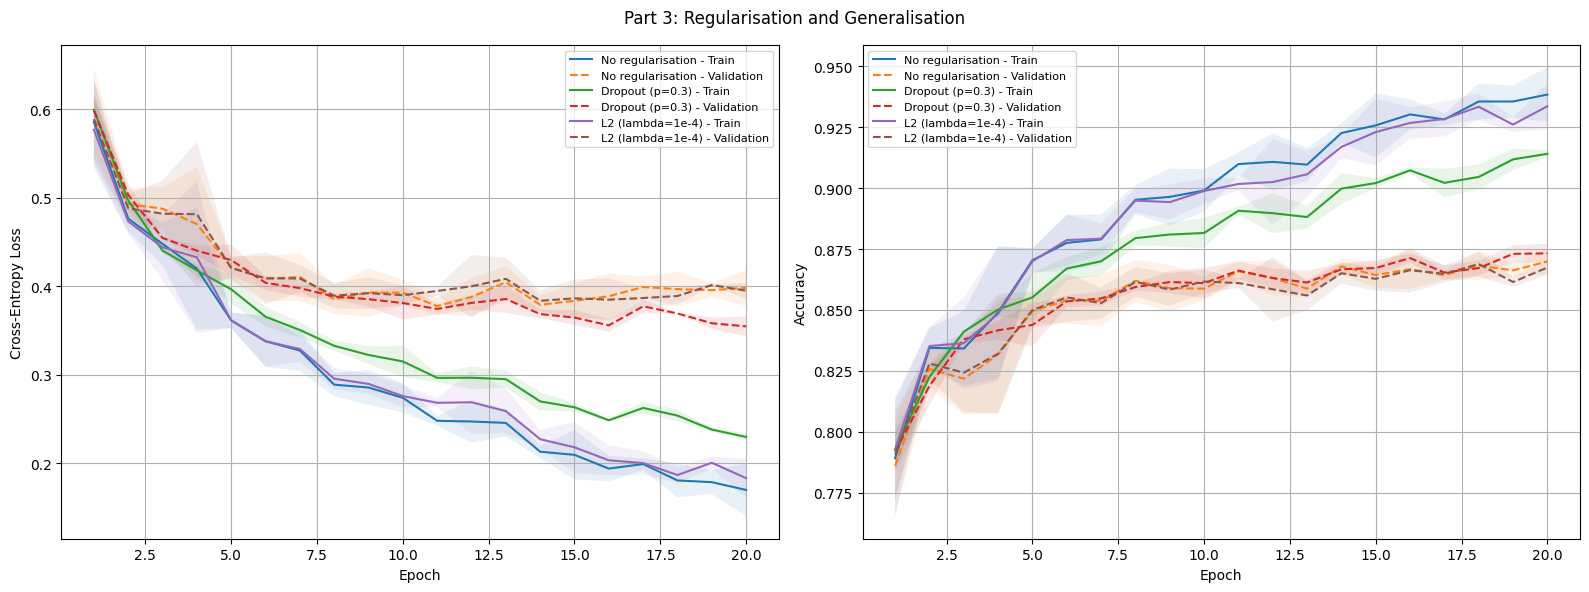

In [ ]:
def plot_part3_curves(results, seeds, config_names):
  fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 6)
  )

  metrics = [
    ("train_ce", "val_ce", "Cross-Entropy Loss"),
    ("train_accuracy", "val_accuracy", "Accuracy")
  ]


  for ax, (train_metric, val_metric, ylabel) in zip(
    axes,
    metrics
  ):
    for config_name in config_names:
      train_histories = []
      val_histories = []

      for seed in seeds:
        history = results[
          (config_name, seed)
        ]["history"].set_index("epoch")


        train_histories.append(
          history[train_metric].rename(seed)
        )

        val_histories.append(
          history[val_metric].rename(seed)
        )


      # Mean and standard deviation across seeds
      train_df = pd.concat(
        train_histories,
        axis=1
      )

      val_df = pd.concat(
        val_histories,
        axis=1
      )

      epochs = train_df.index

      train_mean = train_df.mean(axis=1)
      train_std = train_df.std(axis=1)
      val_mean = val_df.mean(axis=1)
      val_std = val_df.std(axis=1)

      # Training curve
      ax.plot(
        epochs,
        train_mean,
        label=f"{config_name} - Train"
      )

      ax.fill_between(
        epochs,
        train_mean - train_std,
        train_mean + train_std,
        alpha=0.10
      )

      # Validation curve
      ax.plot(
        epochs,
        val_mean,
        linestyle="--",
        label=f"{config_name} - Validation"
      )

      ax.fill_between(
        epochs,
        val_mean - val_std,
        val_mean + val_std,
        alpha=0.10
      )

    ax.set_xlabel("Epoch")
    ax.set_ylabel(ylabel)
    ax.grid(True)
    ax.legend(fontsize=8)

  fig.suptitle(
    "Part 3: Regularisation and Generalisation"
  )

  plt.tight_layout()
  plt.show()

plot_part3_curves(
  results=part3_results,
  seeds=PART3_SEEDS,
  config_names=list(PART3_CONFIGS.keys())
)

In [ ]:
# Create a table:
# Rows = random seeds
# Columns = regularisation configurations

seed_accuracy_pivot = seed_summary_df.pivot(
  index="Seed",
  columns="Configuration",
  values="Best Validation Accuracy"
)


# Compare the main configuration against no regularisation

seed_accuracy_pivot["Dropout Improvement"] = (
  seed_accuracy_pivot["Dropout (p=0.3)"]
  - seed_accuracy_pivot["No regularisation"]
)


seed_accuracy_pivot["L2 Improvement"] = (
  seed_accuracy_pivot["L2 (lambda=1e-4)"]
  - seed_accuracy_pivot["No regularisation"]
)


display(seed_accuracy_pivot)

Configuration,Dropout (p=0.3),L2 (lambda=1e-4),No regularisation,Dropout Improvement,L2 Improvement
Seed,,,,,
45,0.8748,0.8725,0.8707,0.0041,0.0018
46,0.8774,0.8663,0.8678,0.0096,-0.0015
47,0.8703,0.8767,0.8695,0.0008,0.0072


##**Part 4 — Clustering Without Labels**
This part uses K-Means and hierarchical clustering to discover structure without using class labels during fitting. A reproducible sample of 3,000 training images is flattened into 784-dimensional pixel vectors. True labels are stored separately for interpretation and post-clustering evaluation only. Original image arrays are also retained so that cluster assignments can later be connected to visual examples.

In [ ]:
# Part 4 — Clustering: structure without labels
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score

from scipy.cluster.hierarchy import linkage, dendrogram

# Fixed random subset, without using labels

# No labels are used during training here;
# the model discovers similarities and structures within the data on its own rather than label
rng = np.random.default_rng(44)

# Select 3000 images to reduce calculation
cluster_indices = np.sort(
    rng.choice(train_indices, 3000, replace=False)
)

# Flatten image because K-Means cannot be applied to four-dimensional image.
images = torch.stack([
    train_data[i][0] for i in cluster_indices
])

X_cluster = images.flatten(start_dim=1).numpy()

# Keep labels separately for later interpretation only
y_cluster = train_labels[cluster_indices]

images_cluster = images.squeeze(1).numpy()

print(X_cluster.shape)

(3000, 784)


##**Choosing the number of clusters**
K-Means is fitted for several candidate values of K using k-means++ initialisation and ten starts. Inertia measures within-cluster squared distances and generally decreases as K increases; the elbow plot helps identify diminishing returns. Silhouette evaluates cluster cohesion and separation, with higher values usually preferred. It is calculated on the same fixed 1,000-image sample for each candidate K. The notebook chooses the K with the highest tested silhouette score.

In [ ]:
K_values = [2, 5, 8, 10, 12, 15, 20] # k clusters
k_results = []

# Fixed sample for Silhouette
sil_idx = np.random.default_rng(123).choice(
  len(X_cluster),
  size=1000,
  replace=False
)

for k in K_values:
    model = KMeans(
      n_clusters=k,
      init="k-means++",
      n_init=10,
      max_iter=300,
      random_state=44
    )

    labels = model.fit_predict(X_cluster)
    score = silhouette_score(
        X_cluster[sil_idx],
        labels[sil_idx]
    )
    k_results.append({
      "K": k,
      "Inertia": model.inertia_, # The sum of squared distances within clusters
      # Intra-cluster compactness and inter-cluster separation
      "Silhouette": score
    })

k_df = pd.DataFrame(k_results)
display(k_df)

,K,Inertia,Silhouette
0,2,162650.468750,0.197547
1,5,117488.132812,0.171948
2,8,101759.312500,0.163219
3,10,95888.609375,0.156239
4,12,90979.000000,0.134015
5,15,85928.289062,0.126830
6,20,80121.039062,0.116066


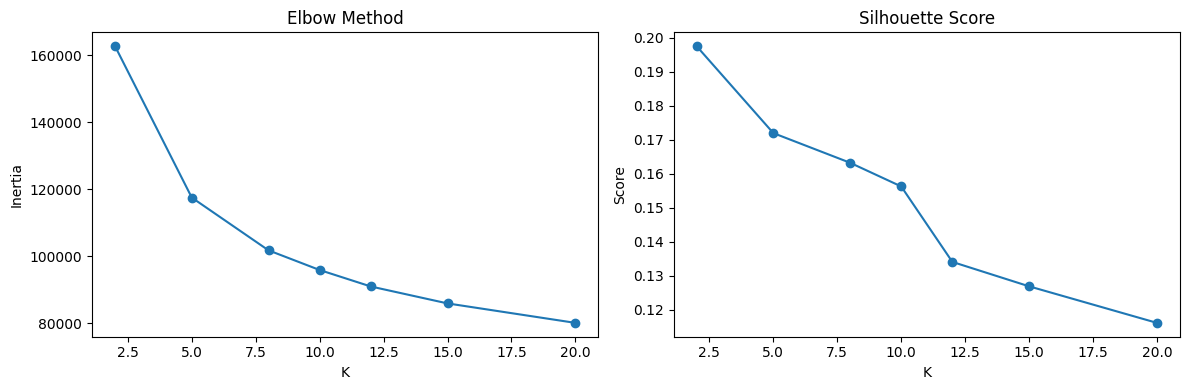

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(k_df["K"], k_df["Inertia"], marker="o")
axes[0].set_title("Elbow Method")
axes[0].set_xlabel("K")
axes[0].set_ylabel("Inertia")

axes[1].plot(k_df["K"], k_df["Silhouette"], marker="o")
axes[1].set_title("Silhouette Score")
axes[1].set_xlabel("K")
axes[1].set_ylabel("Score")

plt.tight_layout()
plt.show()

##**Clustering stability**
The selected K is tested with n_init=1 and n_init=10 across three random seeds. Inertia measures compactness, while pairwise Adjusted Rand Index (ARI) measures similarity between assignments from different runs. Higher ARI indicates more repeatable partitions. These metrics describe different properties: a low-inertia result is not necessarily the most stable. Multiple runs therefore provide information beyond one final clustering fit.

In [ ]:
chosen_k = int(
  k_df.loc[k_df["Silhouette"].idxmax(), "K"]
)

seeds = [11, 22, 33]

stability = {}

for n_init in [1, 10]:
  for seed in seeds:
    model = KMeans(
      n_clusters=chosen_k,
      init="k-means++",
      n_init=n_init,
      max_iter=300,
      random_state=seed
    )

    labels = model.fit_predict(X_cluster)

    stability[(n_init, seed)] = {
      "labels": labels,
      "inertia": model.inertia_
    }

# Pairwise ARI
rows = []

for n_init in [1, 10]:
  aris = []
  for i in range(len(seeds)):
    for j in range(i + 1, len(seeds)):
        a = stability[(n_init, seeds[i])]["labels"]
        b = stability[(n_init, seeds[j])]["labels"]
        aris.append(adjusted_rand_score(a, b))

  rows.append({
    "n_init": n_init,
    "Mean Inertia": np.mean([
      stability[(n_init, s)]["inertia"]
      for s in seeds
    ]),
    "Mean ARI": np.mean(aris)
  })

display(pd.DataFrame(rows))

,n_init,Mean Inertia,Mean ARI
0,1,162650.5625,1.000000
1,10,162650.5000,0.996448


In [ ]:
final_model = KMeans(
  n_clusters=chosen_k,
  init="k-means++",
  n_init=10,
  max_iter=300,
  random_state=44
)

cluster_labels = final_model.fit_predict(X_cluster)

print("Selected K:", chosen_k)
print("Inertia:", final_model.inertia_)

Selected K: 2
Inertia: 162650.46875


##**Interpreting clusters**
A crosstab compares cluster IDs with true class labels after fitting. Raw counts show the number of examples from each class in a cluster; row-normalised values show its class composition. The labels do not influence clustering. A grid of example images helps reveal whether clusters contain one dominant category or mix visually similar items. Cluster IDs are arbitrary group identifiers, not class predictions.

In [ ]:
class_names = train_data.classes

composition = pd.crosstab(
  cluster_labels,
  y_cluster
).reindex(columns=range(10), fill_value=0)

composition.columns = class_names

display(composition)

display(
  composition.div(
    composition.sum(axis=1),
    axis=0
  ).round(3)
)

,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
row_0,,,,,,,,,,
0,60,59,56,92,42,306,86,298,171,296
1,212,249,239,222,263,0,204,0,119,26


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
row_0,,,,,,,,,,
0,0.041,0.040,0.038,0.063,0.029,0.209,0.059,0.203,0.117,0.202
1,0.138,0.162,0.156,0.145,0.171,0.000,0.133,0.000,0.078,0.017


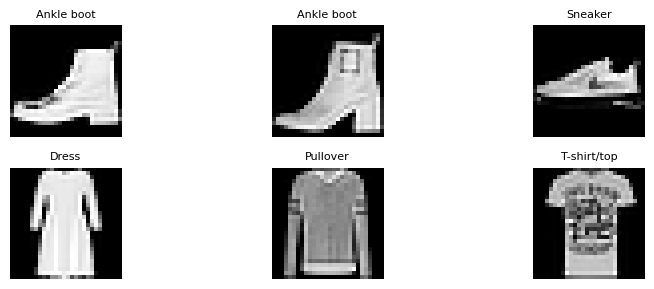

In [ ]:
fig, axes = plt.subplots(
  chosen_k, 3,
  figsize=(9, chosen_k * 1.5),
  squeeze=False
)

rng = np.random.default_rng(123)

for k in range(chosen_k):
  members = np.where(cluster_labels == k)[0]
  selected = rng.choice(
    members,
    size=min(3, len(members)),
    replace=False
  )

  for j, idx in enumerate(selected):
    axes[k, j].imshow(
      images_cluster[idx],
      cmap="gray"
    )

    axes[k, j].set_title(
      class_names[y_cluster[idx]],
      fontsize=8
    )

    axes[k, j].axis("off")

  for j in range(len(selected), 3):
    axes[k, j].axis("off")

plt.tight_layout()
plt.show()

##**Hierarchical clustering**
Ward agglomerative clustering is applied to a fixed subset of 400 images to limit computation. It repeatedly merges groups while minimising the increase in within-cluster variance, using Euclidean distance. The dendrogram displays the larger-scale merge structure. The same K is then used for flat hierarchical clustering and K-Means on the same images. ARI measures agreement between the two partitions, not accuracy against true labels.

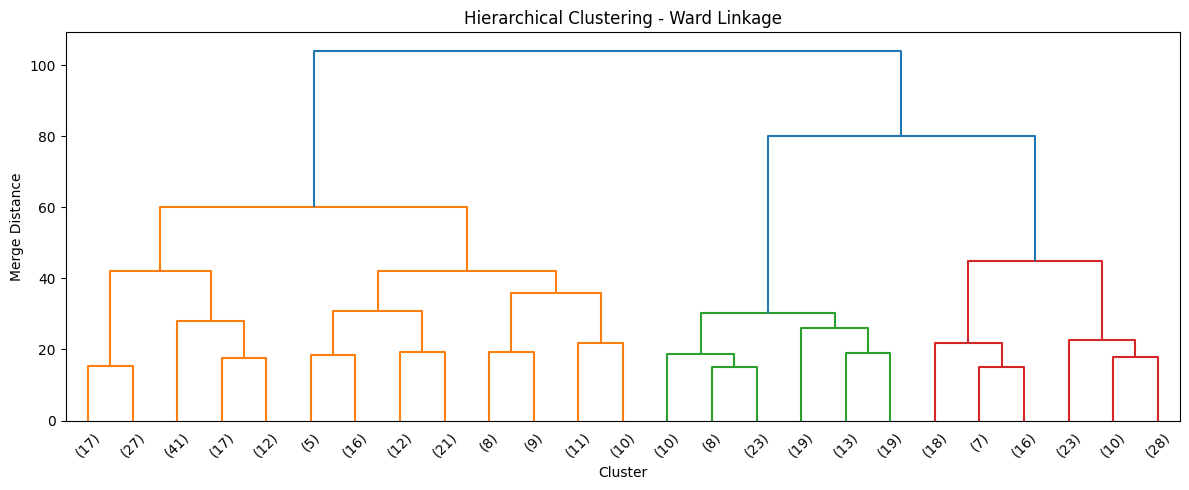

In [ ]:
# Fixed subset of 400 images
rng = np.random.default_rng(404)

idx = np.sort(
  rng.choice(len(X_cluster), 400, replace=False)
)

X_hier = X_cluster[idx]

y_hier = y_cluster[idx]

# Ward linkage
Z = linkage(
  X_hier,
  method="ward",
  metric="euclidean"
)

# Dendrogram
plt.figure(figsize=(12, 5))

dendrogram(
  Z,
  truncate_mode="lastp",
  p=25
)

plt.title("Hierarchical Clustering - Ward Linkage")
plt.xlabel("Cluster")
plt.ylabel("Merge Distance")

plt.tight_layout()
plt.show()

In [ ]:
hier_labels = AgglomerativeClustering(
  n_clusters=chosen_k,
  linkage="ward"
).fit_predict(X_hier)

# Compare with K-means on the same 400 images
kmeans_subset = KMeans(
  n_clusters=chosen_k,
  n_init=10,
  random_state=44
).fit_predict(X_hier)

print(
  "K-means vs Hierarchical ARI:",
  adjusted_rand_score(kmeans_subset, hier_labels)
)

K-means vs Hierarchical ARI: 0.32328462782974604


##**Part 5 — Learned Representations**
This section tests whether clustering changes when images are represented by MLP hidden-layer features instead of raw pixels. A previously trained MLP is selected using its best validation loss. The model is then used as a fixed feature extractor. Raw-pixel and learned-feature experiments use the same images and K-Means settings, so representation is the main changing factor.

In [ ]:
# Part 5 — Representations and one modern extension
# Select the MLP with the lowest validation loss

mlp_candidates = {
  "Small": capacity_results["Small (128, 64)"],
  "Baseline": baseline_result,
  "Large": capacity_results["Large (512, 256)"],
  "Low LR": optimisation_results["LR = 0.0001"],
  "High LR": optimisation_results["LR = 0.01"]
}

# Select the model with minimum validation loss
# Validation set is more convincing.
selected_name, selected_result = min(
  mlp_candidates.items(),
  key=lambda item: item[1]["best_val_loss"]
)

# Get the best model
selected_mlp = selected_result["model"]

print("Selected MLP:", selected_name)
print("Validation loss:", selected_result["best_val_loss"])
print(
  "Feature dimension:",
  selected_mlp.hidden_layers[-1].out_features
)

Selected MLP: Large
Validation loss: 0.3631332562446594
Feature dimension: 256


##**Extracting MLP features**
The selected MLP is placed in evaluation mode and its parameters are frozen. Images are processed in batches of 256 under torch.inference_mode(), which avoids gradient tracking. Each image passes through the hidden layers and ReLU activations; the final hidden-layer activations are collected before the classifier output layer. Concatenating batches creates the learned feature matrix for clustering.

In [ ]:
# Freeze the selected MLP
# Because the MLP no longer serves to train a classifier and it is responsible for feature extraction.
selected_mlp.eval()

for p in selected_mlp.parameters():
  p.requires_grad_(False) # Extract parameters instead of training them

# Select computing device
device = torch.device(
  "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using device:", device)
# Use exactly the same images as Part 4
image_tensor = torch.from_numpy(
  images_cluster
).float().unsqueeze(1)


feature_batches = []

with torch.inference_mode():
  for start in range(0, len(image_tensor), 256): # 256 images each batch
    x = image_tensor[start:start + 256].to(device)
    x = torch.flatten(x, start_dim=1)

    # Pass through hidden layers
    # If multiple Linear layers are stacked in succession without any non-linear activation functions in between,
    # the sequence of linear transformations can ultimately be combined into a single linear transformation.
    for layer in selected_mlp.hidden_layers:
      x = F.relu(layer(x))

    # Extract final hidden-layer activations
    # Transfer features into Numpy and put them together
    feature_batches.append(
      x.cpu().numpy()
    )


X_mlp_features = np.concatenate(
  feature_batches,
  axis=0
)


print("Raw pixel features:", X_cluster.shape)
print("MLP features:", X_mlp_features.shape)
print("MLP feature dimension:", X_mlp_features.shape[1])

Using device: cpu
Raw pixel features: (3000, 784)
MLP features: (3000, 256)
MLP feature dimension: 256


##**Comparing representations**
K-Means is fitted separately to raw pixels and MLP features using identical settings. The table compares feature dimensions, silhouette scores, and ARI against true class labels. Silhouette assesses internal cluster geometry; ARI assesses agreement with known classes. Labels are not used to fit K-Means. These measures answer different questions and may favour different representations, so the accompanying cluster examples provide useful context.

In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

# Exactly the same K-means settings as Part 4
km_settings = {
  "n_clusters": chosen_k,
  "init": "k-means++",
  "n_init": 10,
  "max_iter": 300,
  "random_state": 44
}


# Run K-means in original pixel clustering
raw_kmeans = KMeans(**km_settings)
# fit: Train the K-Means model using the data to find the cluster centers.
# predict: Assign a cluster ID to each image based on the cluster centers.
raw_labels = raw_kmeans.fit_predict(X_cluster)


# Run K-means in MLP feature clustering
mlp_kmeans = KMeans(**km_settings)
mlp_labels = mlp_kmeans.fit_predict(X_mlp_features) # Input mlp features


# Same fixed evaluation images for both representations
compare_idx = np.random.default_rng(123).choice(
  len(X_cluster),
  size=1000,
  replace=False # Sampling without replacement avoids repetition.
)


comparison = pd.DataFrame({
  "Representation": [
    "Raw Pixels",
    "MLP Features"
  ],

  "Dimensions": [
    X_cluster.shape[1],
    X_mlp_features.shape[1]
  ],

  "Silhouette": [
    silhouette_score(
      X_cluster[compare_idx],
      raw_labels[compare_idx]
    ),

    silhouette_score(
      X_mlp_features[compare_idx],
      mlp_labels[compare_idx]
    )
  ],

  # Labels are used only for post-clustering evaluation
  "ARI vs True Labels": [
    adjusted_rand_score(
      y_cluster,
      raw_labels
    ),

    adjusted_rand_score(
      y_cluster,
      mlp_labels
    )
  ]

})

display(comparison)

,Representation,Dimensions,Silhouette,ARI vs True Labels
0,Raw Pixels,784,0.197547,0.094960
1,MLP Features,256,0.282345,0.151508


Raw Pixel Clusters


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
row_0,,,,,,,,,,
0,60,59,56,92,42,306,86,298,171,296
1,212,249,239,222,263,0,204,0,119,26


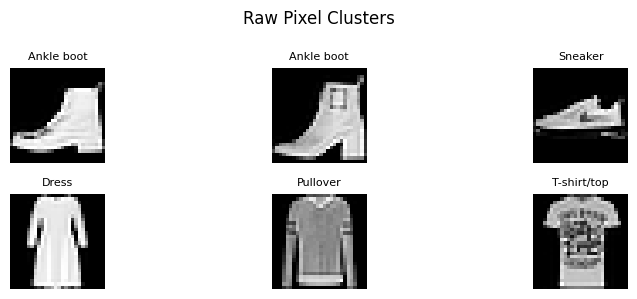

MLP Feature Clusters


,T-shirt/top,Trouser,Pullover,Dress,Coat,Sandal,Shirt,Sneaker,Bag,Ankle boot
row_0,,,,,,,,,,
0,0,0,0,0,0,305,0,298,11,322
1,272,308,295,314,305,1,290,0,279,0


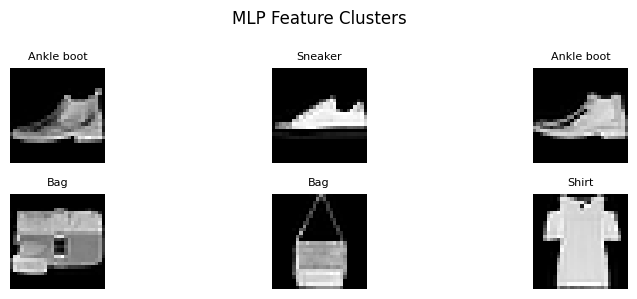

In [ ]:
class_names = train_data.classes

def show_representation_clusters(labels, title):
  composition = pd.crosstab(
    labels,
    y_cluster
  ).reindex(
    columns=range(10),
    fill_value=0
  )

  composition.columns = class_names

  print(title)
  display(composition)

  # 3 example images per cluster
  fig, axes = plt.subplots(
    chosen_k, 3,
    figsize=(9, chosen_k * 1.5),
    squeeze=False
  )

  rng = np.random.default_rng(123)

  for k in range(chosen_k):
    members = np.where(labels == k)[0]
    selected = rng.choice(
        members,
        size=min(3, len(members)),
        replace=False
    )

    for j, idx in enumerate(selected):
      axes[k, j].imshow(
        images_cluster[idx],
        cmap="gray"
      )
      axes[k, j].set_title(
        class_names[y_cluster[idx]],
        fontsize=8
      )
      axes[k, j].axis("off")

    for j in range(len(selected), 3):
      axes[k, j].axis("off")

  plt.suptitle(title)
  plt.tight_layout()
  plt.show()


show_representation_clusters(
  raw_labels,
  "Raw Pixel Clusters"
)

show_representation_clusters(
  mlp_labels,
  "MLP Feature Clusters"
)

##**Part 6 — Probability Ensembling**
The final section combines Logistic Regression and Random Forest probabilities. predict_proba_10 places probabilities into a fixed ten-column array according to each model's classes_ order, ensuring corresponding columns represent the same class. Probabilities are generated for validation and test data. Validation results select the ensemble weight; test data is retained for final reporting after selection.

In [ ]:
#%%writefile -a src/evaluate.py
def loader_to_numpy(loader): # Transfer data into numpy format
  X, y = [], []

  for images, labels in loader:
    X.append(
      images.flatten(start_dim=1).numpy()
    )
    y.append(labels.numpy())

  return ( # concatenate batches
    np.concatenate(X), # image features
    np.concatenate(y) # image labels
  )


X_test_classical, y_test_classical = loader_to_numpy(
  test_loader
)


# Make probability columns follow class labels 0-9
def predict_proba_10(model, X):
  # The probability of each sample belonging to each category
  probabilities = model.predict_proba(X)
  result = np.zeros( # Create a fixed 10-column matrix
    (len(X), 10)
  )
  # Place the raw predicted probabilities into the positions corresponding to their respective classes.
  result[:, model.classes_.astype(int)] = probabilities
  return result


# Validation probabilities
# Predicted probabilities from the LR model on the validation set
val_lr_prob = predict_proba_10(
  lr_model,
  X_val_classical
)

# Predicted probabilities from the RF model on the validation set
val_rf_prob = predict_proba_10(
  rf_model,
  X_val_classical
)


# Test probabilities
test_lr_prob = predict_proba_10(
  lr_model,
  X_test_classical
)

test_rf_prob = predict_proba_10(
  rf_model,
  X_test_classical
)

##**Selecting the ensemble weight**
The ensemble averages the two probability matrices, with alpha controlling the Logistic Regression contribution and 1 - alpha controlling Random Forest. Three candidate weights—0.25, 0.50, and 0.75—are tested on validation data. The candidate with the highest validation accuracy becomes best_alpha. This is a small grid search, so the selected value is best only among the tested weights

In [ ]:
#%%writefile -a src/evaluate.py
from sklearn.metrics import accuracy_score

weights = [0.25, 0.5, 0.75]
weight_results = []

for alpha in weights:
  ensemble_prob = ( # Combining probabilities from LR and RF on the validation set
    alpha * val_lr_prob
    + (1 - alpha) * val_rf_prob
  )
  pred = ensemble_prob.argmax(axis=1) # Select the category with the highest probability for each image.
  acc = accuracy_score(
    y_val_classical,
    pred
  )
  weight_results.append({
    "LR Weight": alpha,
    "RF Weight": 1 - alpha,
    "Validation Accuracy": acc
  })


weight_df = pd.DataFrame(weight_results)
display(weight_df)


# Select the best weight using validation accuracy
best_alpha = weight_df.loc[
  weight_df["Validation Accuracy"].idxmax(),
  "LR Weight"
]

print("Selected LR weight:", best_alpha)
print("Selected RF weight:", 1 - best_alpha)

,LR Weight,RF Weight,Validation Accuracy
0,0.25,0.75,0.8680
1,0.50,0.50,0.8599
2,0.75,0.25,0.8501


Selected LR weight: 0.25
Selected RF weight: 0.75


##**Final evaluation**
The selected weight is applied unchanged to validation and test probabilities. A shared function calculates accuracy for Logistic Regression, Random Forest, and the ensemble. The test classification report then provides precision, recall, F1-score, and support for every class. Because weight selection used validation data, test results remain the final independent evaluation and should not be used to retune the ensemble.

In [ ]:
#%%writefile -a src/evaluate.py
# Ensemble probabilities
# Combine the predicted probabilities from two models with the best weights
val_ensemble_prob = (
  best_alpha * val_lr_prob
  + (1 - best_alpha) * val_rf_prob
)

test_ensemble_prob = (
  best_alpha * test_lr_prob
  + (1 - best_alpha) * test_rf_prob
)

# Organize data
models_val = {
  "Logistic Regression": val_lr_prob,
  "Random Forest": val_rf_prob,
  "Ensemble": val_ensemble_prob
}

models_test = {
  "Logistic Regression": test_lr_prob,
  "Random Forest": test_rf_prob,
  "Ensemble": test_ensemble_prob
}


def overall_results(models, y_true):
  rows = []

  for name, probabilities in models.items():
    predictions = probabilities.argmax(axis=1)
    rows.append({
      "Model": name,
      "Accuracy": accuracy_score(
        y_true,
        predictions
      )
    })

  return pd.DataFrame(rows)


print("Validation Results")

display(
  overall_results(
    models_val,
    y_val_classical
  )
)


print("Test Results")

display(
  overall_results(
    models_test,
    y_test_classical
  )
)

Validation Results


,Model,Accuracy
0,Logistic Regression,0.8412
1,Random Forest,0.8603
2,Ensemble,0.8680


Test Results


,Model,Accuracy
0,Logistic Regression,0.8271
1,Random Forest,0.8493
2,Ensemble,0.8559


In [ ]:
#%%writefile -a src/evaluate.py
# Show Datas
from sklearn.metrics import classification_report

class_results = []

for name, probabilities in models_test.items():
  predictions = probabilities.argmax(axis=1)
  report = classification_report(
    y_test_classical,
    predictions,
    labels=np.arange(10),
    target_names=class_names,
    output_dict=True,
    zero_division=0
  )

  for class_name in class_names:
    class_results.append({
      "Model": name,
      "Class": class_name,
      "Precision": report[class_name]["precision"],
      "Recall": report[class_name]["recall"],
      "F1": report[class_name]["f1-score"],
      "Support": report[class_name]["support"]
    })


class_results_df = pd.DataFrame(class_results)
display(class_results_df)

,Model,Class,Precision,Recall,F1,Support
0,Logistic Regression,T-shirt/top,0.767241,0.801,0.783757,1000.0
1,Logistic Regression,Trouser,0.968367,0.949,0.958586,1000.0
2,Logistic Regression,Pullover,0.687023,0.720,0.703125,1000.0
3,Logistic Regression,Dress,0.841513,0.823,0.832154,1000.0
4,Logistic Regression,Coat,0.728079,0.739,0.733499,1000.0
5,Logistic Regression,Sandal,0.935185,0.909,0.921907,1000.0
6,Logistic Regression,Shirt,0.591948,0.544,0.566962,1000.0
7,Logistic Regression,Sneaker,0.898239,0.918,0.908012,1000.0
8,Logistic Regression,Bag,0.926221,0.929,0.927609,1000.0
9,Logistic Regression,Ankle boot,0.921492,0.939,0.930163,1000.0


##**Inference benchmark**
Each model is warmed up on a small batch, then timed three times on the full 10,000-image test set using time.perf_counter(). The mean elapsed time is reported as total seconds and milliseconds per image. The ensemble runs both classifiers, so its time includes both probability calculations. These measurements describe the current runtime and hardware, not universal model speeds.

In [ ]:
import time
# Calculate the tims
def benchmark_inference(function, X, repeats=3):
  # Warm-up
  function(X[:256])
  times = []
  for _ in range(repeats):
    start = time.perf_counter()
    function(X)
    elapsed = time.perf_counter() - start
    times.append(elapsed)
  return np.mean(times)


def ensemble_predict(X):
  p1 = predict_proba_10(lr_model, X)
  p2 = predict_proba_10(rf_model, X)
  return best_alpha * p1 + (1 - best_alpha) * p2


inference_times = {

  "Logistic Regression": benchmark_inference(
    lambda X: predict_proba_10(lr_model, X),
    X_test_classical
  ),

  "Random Forest": benchmark_inference(
    lambda X: predict_proba_10(rf_model, X),
    X_test_classical
  ),

  "Ensemble": benchmark_inference(
    ensemble_predict,
    X_test_classical
  )
}


cost_df = pd.DataFrame({
  "Model": list(inference_times.keys()),
  "Time for 10000 images (seconds)": list(
    inference_times.values()
  ),

})

cost_df["Milliseconds per image"] = (
  cost_df["Time for 10000 images (seconds)"]
  / len(X_test_classical)
  * 1000
)

display(cost_df)

,Model,Time for 10000 images (seconds),Milliseconds per image
0,Logistic Regression,0.139601,0.013960
1,Random Forest,0.927098,0.092710
2,Ensemble,1.053357,0.105336


##**Reproducing data partitions**
This cell independently reloads Fashion-MNIST and repeats the split and sampling operations with the same seeds. Exporting indices makes it possible to recreate the same subsets in separate scripts or clean sessions. The saved index arrays record which examples were used, while the CSV outputs in subsequent cells preserve metrics and training histories. Together they make the experimental workflow easier to audit and reproduce.

In [ ]:
import numpy as np
from pathlib import Path

from torchvision import datasets, transforms
from sklearn.model_selection import train_test_split


# 1. Load original datasets
transform = transforms.ToTensor()

train_data = datasets.FashionMNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.FashionMNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

train_labels = train_data.targets.numpy()
test_labels = test_data.targets.numpy()


# 2. Original random seeds
SEED_SPLIT = 42
SEED_CPU = 43
SEED_CLUSTER = 44


# 3. Reproduce Cell 27
train_all_indices = np.arange(len(train_data))

train_50k_indices, val_indices = train_test_split(
    train_all_indices,
    test_size=10000,
    random_state=SEED_SPLIT,
    stratify=train_labels
)


# 4. Reproduce Cell 28
def stratified_sample(
    base_indices,
    labels,
    n_samples,
    seed
):
    local_indices = np.arange(len(base_indices))

    selected_local, _ = train_test_split(
        local_indices,
        train_size=n_samples,
        random_state=seed,
        stratify=labels[base_indices]
    )

    return base_indices[selected_local]


train_indices = stratified_sample(
    train_50k_indices,
    train_labels,
    n_samples=10000,
    seed=SEED_CPU
)


# 5. Reproduce Cell 29
cluster_train_indices = stratified_sample(
    train_indices,
    train_labels,
    n_samples=3000,
    seed=SEED_CLUSTER
)

cluster_val_indices = stratified_sample(
    val_indices,
    train_labels,
    n_samples=1000,
    seed=SEED_CLUSTER
)

test_all_indices = np.arange(len(test_data))

cluster_test_indices = stratified_sample(
    test_all_indices,
    test_labels,
    n_samples=1000,
    seed=SEED_CLUSTER
)


# 6. Reproduce Cell 73
rng = np.random.default_rng(44)

cluster_indices = np.sort(
    rng.choice(
        train_indices,
        3000,
        replace=False
    )
)


# 7. Reproduce Cell 74
sil_idx = np.random.default_rng(123).choice(
    len(cluster_indices),
    size=1000,
    replace=False
)


# 8. Reproduce Cell 80
idx = np.sort(
    np.random.default_rng(404).choice(
        len(cluster_indices),
        400,
        replace=False
    )
)


# 9. Reproduce Cell 84
compare_idx = np.random.default_rng(123).choice(
    len(cluster_indices),
    size=1000,
    replace=False
)


# 10. Save all indices
SPLIT_DIR = Path("splits")
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

np.savez_compressed(
    SPLIT_DIR / "fashion_mnist_indices.npz",

    # Random seeds
    seed_split=SEED_SPLIT,
    seed_cpu=SEED_CPU,
    seed_cluster=SEED_CLUSTER,

    seed_silhouette=123,
    seed_hierarchical=404,
    seed_representation=123,

    # Main dataset
    train_50k_indices=train_50k_indices,
    train_indices=train_indices,
    val_indices=val_indices,
    test_indices=test_all_indices,

    # Cell 29 subsets
    cluster_train_indices=cluster_train_indices,
    cluster_val_indices=cluster_val_indices,
    cluster_test_indices=cluster_test_indices,

    # Cell 73 clustering samples
    part4_cluster_indices=cluster_indices,

    # Cell 74
    silhouette_local_indices=sil_idx,
    silhouette_global_indices=cluster_indices[sil_idx],

    # Cell 80
    hierarchical_local_indices=idx,
    hierarchical_global_indices=cluster_indices[idx],

    # Cell 84
    representation_local_indices=compare_idx,
    representation_global_indices=cluster_indices[compare_idx]
)


# 11. Verify
saved = np.load(
    SPLIT_DIR / "fashion_mnist_indices.npz"
)

print("Splits exported successfully!\n")

for key in saved.files:
    print(f"{key}: {saved[key].shape}")

print("\nFile:", SPLIT_DIR / "fashion_mnist_indices.npz")

Splits exported successfully!

seed_split: ()
seed_cpu: ()
seed_cluster: ()
seed_silhouette: ()
seed_hierarchical: ()
seed_representation: ()
train_50k_indices: (50000,)
train_indices: (10000,)
val_indices: (10000,)
test_indices: (10000,)
cluster_train_indices: (3000,)
cluster_val_indices: (1000,)
cluster_test_indices: (1000,)
part4_cluster_indices: (3000,)
silhouette_local_indices: (1000,)
silhouette_global_indices: (1000,)
hierarchical_local_indices: (400,)
hierarchical_global_indices: (400,)
representation_local_indices: (1000,)
representation_global_indices: (1000,)

File: splits/fashion_mnist_indices.npz


In [ ]:
accuracy_comparison.to_csv(
    "results/classical_validation_accuracy.csv",
    index=False
)

In [ ]:
lr_complexity_df.to_csv(
    "results/lr_complexity_results.csv",
    index=False
)

rf_complexity_df.to_csv(
    "results/rf_complexity_results.csv",
    index=False
)

threshold_df.to_csv(
    "results/footwear_threshold_results.csv",
    index=False
)

capacity_summary_df.to_csv(
    "results/mlp_capacity_results.csv",
    index=False
)

optimisation_summary_df.to_csv(
    "results/mlp_optimisation_results.csv",
    index=False
)

seed_summary_df.to_csv(
    "results/mlp_regularisation_results.csv",
    index=False
)

randomness_summary.to_csv(
    "results/mlp_regularisation_summary.csv"
)

k_df.to_csv(
    "results/clustering_k_selection.csv",
    index=False
)

composition.to_csv(
    "results/clustering_composition.csv"
)

comparison.to_csv(
    "results/representation_comparison.csv",
    index=False
)

weight_df.to_csv(
    "results/ensemble_weights.csv",
    index=False
)

class_results_df.to_csv(
    "results/ensemble_classification_report.csv",
    index=False
)

cost_df.to_csv(
    "results/inference_benchmark.csv",
    index=False
)

In [ ]:
baseline_result["history"].to_csv(
    "results/logs/mlp_baseline_history.csv",
    index=False
)

capacity_results["Small (128, 64)"]["history"].to_csv(
    "results/logs/mlp_capacity_small_history.csv",
    index=False
)

capacity_results["Large (512, 256)"]["history"].to_csv(
    "results/logs/mlp_capacity_large_history.csv",
    index=False
)

optimisation_results["LR = 0.0001"]["history"].to_csv(
    "results/logs/mlp_lr_low_history.csv",
    index=False
)

optimisation_results["LR = 0.01"]["history"].to_csv(
    "results/logs/mlp_lr_high_history.csv",
    index=False
)

from pathlib import Path
import re

log_dir = Path("results/logs")
log_dir.mkdir(parents=True, exist_ok=True)

for (config_name, seed), result in part3_results.items():

    filename = re.sub(
        r"[^a-zA-Z0-9]+",
        "_",
        config_name
    ).strip("_").lower()

    result["history"].to_csv(
        log_dir / f"{filename}_seed{seed}.csv",
        index=False
    )